In [1]:
!pip install -U pandas requests biopython tqdm openpyxl tenacity


[notice] A new release of pip is available: 25.1.1 -> 26.1.1
[notice] To update, run: python.exe -m pip install --upgrade pip


In [2]:
from pathlib import Path
import time
import re
import requests
import pandas as pd
from tqdm import tqdm
from tenacity import retry, stop_after_attempt, wait_exponential
from Bio import Entrez, Medline


# =========================
# 0. Settings
# =========================

OUTPUT_DIR = Path(r"D:\Pycharm\JupyterProject1\ai_gait_restart")
OUTPUT_DIR.mkdir(parents=True, exist_ok=True)

Entrez.email = "your_email@example.com"  # 改成你的邮箱

YEAR_MIN = 2015
MAX_PER_QUERY_PUBMED = 200
MAX_PER_QUERY_S2 = 200

SEARCH_QUERIES = {
    "A_stroke_ai_gait": '''
        (stroke OR post-stroke OR hemiplegia)
        AND
        (gait OR walking OR locomotion)
        AND
        ("artificial intelligence" OR "machine learning" OR "deep learning" OR "computer vision" OR "pose estimation" OR markerless)
    ''',

    "B_video_markerless_clinical_gait": '''
        ("video-based gait analysis" OR "markerless gait analysis" OR "pose estimation")
        AND
        (clinical OR rehabilitation OR patient OR neurological)
    ''',

    "C_llm_vlm_gait": '''
        ("large language model" OR LLM OR GPT OR "vision language model" OR VLM)
        AND
        (gait OR walking OR "motion analysis" OR rehabilitation)
    ''',

    "D_ai_gait_parameters": '''
        ("gait analysis" OR "gait assessment")
        AND
        (spatiotemporal OR kinematic OR "joint angle" OR "toe clearance" OR symmetry)
        AND
        ("machine learning" OR "deep learning" OR "computer vision" OR algorithm)
    ''',

    "E_ml_gait_review": '''
        ("machine learning" OR "artificial intelligence")
        AND
        ("gait analysis" OR "gait rehabilitation")
        AND
        (review OR "systematic review")
    '''
}

In [3]:
def search_pubmed(query_name, query, max_results=200, year_min=2015):
    """
    Search PubMed via NCBI E-utilities.
    """
    date_filter = f'("{year_min}"[Date - Publication] : "3000"[Date - Publication])'
    final_query = f"({query}) AND {date_filter}"

    handle = Entrez.esearch(
        db="pubmed",
        term=final_query,
        retmax=max_results,
        sort="relevance"
    )
    record = Entrez.read(handle)
    pmids = record.get("IdList", [])

    if not pmids:
        return pd.DataFrame()

    handle = Entrez.efetch(
        db="pubmed",
        id=",".join(pmids),
        rettype="medline",
        retmode="text"
    )

    records = list(Medline.parse(handle))

    rows = []
    for r in records:
        doi_list = [
            aid.replace(" [doi]", "")
            for aid in r.get("AID", [])
            if "[doi]" in aid
        ]

        rows.append({
            "retrieval_source": "PubMed",
            "query_name": query_name,
            "pmid": r.get("PMID", ""),
            "title": r.get("TI", ""),
            "abstract": r.get("AB", ""),
            "journal": r.get("JT", ""),
            "year": str(r.get("DP", ""))[:4],
            "doi": "; ".join(doi_list),
            "authors": "; ".join(r.get("AU", [])),
            "url": f"https://pubmed.ncbi.nlm.nih.gov/{r.get('PMID', '')}/"
        })

    return pd.DataFrame(rows)

In [4]:
@retry(stop=stop_after_attempt(3), wait=wait_exponential(multiplier=1, min=2, max=10))
def s2_request(url, params):
    r = requests.get(url, params=params, timeout=30)
    r.raise_for_status()
    return r.json()


def search_semantic_scholar(query_name, query, max_results=200, year_min=2015):
    """
    Search Semantic Scholar Graph API.
    """
    url = "https://api.semanticscholar.org/graph/v1/paper/search"
    fields = "title,abstract,year,authors,venue,externalIds,url,citationCount,fieldsOfStudy"

    rows = []
    limit = 100

    for offset in range(0, max_results, limit):
        params = {
            "query": query,
            "limit": limit,
            "offset": offset,
            "fields": fields
        }

        try:
            data = s2_request(url, params)
        except Exception as e:
            print(f"Semantic Scholar failed for {query_name}, offset {offset}: {e}")
            break

        papers = data.get("data", [])
        if not papers:
            break

        for p in papers:
            year = p.get("year")
            if year is not None and year < year_min:
                continue

            external_ids = p.get("externalIds") or {}
            authors = p.get("authors") or []

            rows.append({
                "retrieval_source": "Semantic Scholar",
                "query_name": query_name,
                "pmid": external_ids.get("PubMed", ""),
                "title": p.get("title", ""),
                "abstract": p.get("abstract", ""),
                "journal": p.get("venue", ""),
                "year": year,
                "doi": external_ids.get("DOI", ""),
                "authors": "; ".join([a.get("name", "") for a in authors]),
                "url": p.get("url", ""),
                "citation_count": p.get("citationCount", None),
                "fields_of_study": "; ".join(p.get("fieldsOfStudy") or [])
            })

        time.sleep(1)

    return pd.DataFrame(rows)

In [5]:
all_results = []

for query_name, query in SEARCH_QUERIES.items():
    print("\n==============================")
    print("Running query:", query_name)
    print("==============================")

    print("Searching PubMed...")
    pubmed_df = search_pubmed(
        query_name=query_name,
        query=query,
        max_results=MAX_PER_QUERY_PUBMED,
        year_min=YEAR_MIN
    )
    print("PubMed results:", len(pubmed_df))
    all_results.append(pubmed_df)

    print("Searching Semantic Scholar...")
    s2_df = search_semantic_scholar(
        query_name=query_name,
        query=query,
        max_results=MAX_PER_QUERY_S2,
        year_min=YEAR_MIN
    )
    print("Semantic Scholar results:", len(s2_df))
    all_results.append(s2_df)


retrieval_df = pd.concat(all_results, ignore_index=True)

raw_path = OUTPUT_DIR / "01_raw_retrieval_pubmed_s2.csv"
retrieval_df.to_csv(raw_path, index=False, encoding="utf-8-sig")
retrieval_df.to_excel(raw_path.with_suffix(".xlsx"), index=False)

print("\nRaw retrieval rows:", len(retrieval_df))
print("Saved to:", raw_path)


Running query: A_stroke_ai_gait
Searching PubMed...
PubMed results: 200
Searching Semantic Scholar...
Semantic Scholar results: 0

Running query: B_video_markerless_clinical_gait
Searching PubMed...
PubMed results: 200
Searching Semantic Scholar...
Semantic Scholar failed for B_video_markerless_clinical_gait, offset 0: RetryError[<Future at 0x125396188a0 state=finished raised HTTPError>]
Semantic Scholar results: 0

Running query: C_llm_vlm_gait
Searching PubMed...
PubMed results: 200
Searching Semantic Scholar...
Semantic Scholar failed for C_llm_vlm_gait, offset 0: RetryError[<Future at 0x12539547240 state=finished raised HTTPError>]
Semantic Scholar results: 0

Running query: D_ai_gait_parameters
Searching PubMed...
PubMed results: 200
Searching Semantic Scholar...
Semantic Scholar results: 0

Running query: E_ml_gait_review
Searching PubMed...
PubMed results: 104
Searching Semantic Scholar...
Semantic Scholar failed for E_ml_gait_review, offset 0: RetryError[<Future at 0x1253950fa

In [8]:
import re
import pandas as pd


def normalize_title(title):
    title = str(title).lower()
    title = re.sub(r"[^a-z0-9 ]+", " ", title)
    title = re.sub(r"\s+", " ", title).strip()
    return title


def merge_unique_values(series):
    values = []
    for x in series.dropna():
        for item in str(x).split(";"):
            item = item.strip()
            if item and item.lower() not in ["nan", "none"]:
                if item not in values:
                    values.append(item)
    return "; ".join(values)


# =========================
# 1. Ensure required columns exist
# =========================

required_cols = [
    "retrieval_source",
    "query_name",
    "pmid",
    "title",
    "abstract",
    "journal",
    "year",
    "doi",
    "authors",
    "url",
    "citation_count",
    "fields_of_study"
]

for col in required_cols:
    if col not in retrieval_df.columns:
        retrieval_df[col] = ""

print("Columns after fixing:")
print(retrieval_df.columns.tolist())


# =========================
# 2. Normalize title and DOI
# =========================

retrieval_df["title_norm"] = retrieval_df["title"].apply(normalize_title)

retrieval_df["doi_norm"] = (
    retrieval_df["doi"]
    .fillna("")
    .astype(str)
    .str.lower()
    .str.strip()
)

# 把 nan / none 这种字符串也当作空 DOI
retrieval_df.loc[
    retrieval_df["doi_norm"].isin(["nan", "none", ""]),
    "doi_norm"
] = ""


# =========================
# 3. DOI first; if no DOI, use normalized title
# =========================

retrieval_df["dedup_key"] = retrieval_df["doi_norm"]

retrieval_df.loc[
    retrieval_df["dedup_key"] == "",
    "dedup_key"
] = retrieval_df["title_norm"]


# 删除没有 title 的空记录
retrieval_df = retrieval_df[
    retrieval_df["dedup_key"].notna() &
    (retrieval_df["dedup_key"].astype(str).str.strip() != "")
].copy()


# =========================
# 4. Aggregate duplicates
# =========================

agg_dict = {
    "retrieval_source": merge_unique_values,
    "query_name": merge_unique_values,
    "pmid": merge_unique_values,
    "title": "first",
    "abstract": "first",
    "journal": "first",
    "year": "first",
    "doi": "first",
    "authors": "first",
    "url": "first",
    "fields_of_study": merge_unique_values,
    "title_norm": "first",
    "doi_norm": "first"
}

# citation_count 可能是空字符串，先转成数字
retrieval_df["citation_count"] = pd.to_numeric(
    retrieval_df["citation_count"],
    errors="coerce"
)

agg_dict["citation_count"] = "max"


dedup_df = retrieval_df.groupby("dedup_key", as_index=False).agg(agg_dict)


# =========================
# 5. Save
# =========================

dedup_path = OUTPUT_DIR / "02_deduplicated_retrieval.csv"

dedup_df.to_csv(dedup_path, index=False, encoding="utf-8-sig")
dedup_df.to_excel(dedup_path.with_suffix(".xlsx"), index=False)

print("Before dedup:", len(retrieval_df))
print("After dedup:", len(dedup_df))
print("Saved to:", dedup_path)

Columns after fixing:
['retrieval_source', 'query_name', 'pmid', 'title', 'abstract', 'journal', 'year', 'doi', 'authors', 'url', 'title_norm', 'doi_norm', 'dedup_key', 'citation_count', 'fields_of_study']
Before dedup: 904
After dedup: 847
Saved to: D:\Pycharm\JupyterProject1\ai_gait_restart\02_deduplicated_retrieval.csv


In [9]:
def build_text(row):
    fields = [
        "title",
        "abstract",
        "journal",
        "fields_of_study",
        "query_name"
    ]
    parts = []
    for f in fields:
        if f in row.index and not pd.isna(row[f]):
            parts.append(str(row[f]))
    return " ".join(parts).lower()


def has_any(text, terms):
    return any(term.lower() in text for term in terms)


def rule_screen(row):
    text = build_text(row)

    # Exclude obvious irrelevant studies
    if has_any(text, [
        "person re-identification",
        "person reidentification",
        "identity recognition",
        "biometric authentication",
        "gait recognition for identification"
    ]):
        return "exclude_identity_recognition"

    if has_any(text, [
        "mouse gait", "mice gait", "rat gait", "rodent gait",
        "canine gait", "dog gait", "animal model"
    ]):
        return "exclude_animal"

    if has_any(text, [
        "emotion recognition", "emotional state", "affective computing"
    ]):
        return "exclude_emotion"

    if has_any(text, [
        "athlete", "sprint", "running economy", "sports performance"
    ]) and not has_any(text, [
        "patient", "clinical", "rehabilitation", "stroke",
        "parkinson", "osteoarthritis", "neurological"
    ]):
        return "exclude_sports_only"

    # Strong include signals
    has_gait = has_any(text, [
        "gait", "walking", "locomotion", "mobility"
    ])

    has_ai = has_any(text, [
        "artificial intelligence", "machine learning", "deep learning",
        "neural network", "computer vision", "pose estimation",
        "markerless", "algorithm", "transformer", "gpt",
        "large language model", "vision language model"
    ])

    has_video_pose_sensor = has_any(text, [
        "video", "camera", "monocular", "rgb", "markerless",
        "pose estimation", "keypoint", "skeleton", "wearable",
        "imu", "inertial", "sensor"
    ])

    has_clinical = has_any(text, [
        "stroke", "post-stroke", "hemiplegia", "parkinson",
        "multiple sclerosis", "cerebral palsy", "osteoarthritis",
        "rehabilitation", "clinical", "patient", "patients",
        "fall risk", "older adults", "neurological"
    ])

    has_gait_features = has_any(text, [
        "spatiotemporal", "temporospatial", "kinematic",
        "joint angle", "cadence", "step length", "stride length",
        "stance time", "swing time", "toe clearance", "symmetry",
        "ground reaction force"
    ])

    if has_gait and has_ai and has_video_pose_sensor and has_clinical:
        return "include_candidate_high"

    if has_gait and has_ai and (has_video_pose_sensor or has_gait_features):
        return "include_candidate_medium"

    if has_gait and (has_clinical or has_gait_features):
        return "maybe_background"

    return "exclude_low_relevance"


dedup_df["rule_screening_label"] = dedup_df.apply(rule_screen, axis=1)

print(dedup_df["rule_screening_label"].value_counts())

screened_path = OUTPUT_DIR / "03_rule_screened.csv"
dedup_df.to_csv(screened_path, index=False, encoding="utf-8-sig")
dedup_df.to_excel(screened_path.with_suffix(".xlsx"), index=False)

print("Saved to:", screened_path)

rule_screening_label
include_candidate_high      443
maybe_background            266
include_candidate_medium     88
exclude_low_relevance        38
exclude_emotion               5
exclude_sports_only           4
exclude_animal                3
Name: count, dtype: int64
Saved to: D:\Pycharm\JupyterProject1\ai_gait_restart\03_rule_screened.csv


### 重新跑规则筛选 V2

In [10]:
from pathlib import Path
import pandas as pd
import re

OUTPUT_DIR = Path(r"D:\Pycharm\JupyterProject1\ai_gait_restart")

DEDUP_CSV = OUTPUT_DIR / "02_deduplicated_retrieval.csv"

dedup_df = pd.read_csv(DEDUP_CSV)

print("Deduplicated rows:", len(dedup_df))
print(dedup_df.columns.tolist())

Deduplicated rows: 847
['dedup_key', 'retrieval_source', 'query_name', 'pmid', 'title', 'abstract', 'journal', 'year', 'doi', 'authors', 'url', 'fields_of_study', 'title_norm', 'doi_norm', 'citation_count']


In [11]:
def normalize_text(x):
    if pd.isna(x):
        return ""
    return str(x).lower()


def build_actual_text(row):
    """
    Only use title and abstract for screening.
    Do NOT use query_name, because query names contain gait/AI/stroke words.
    """
    title = normalize_text(row.get("title", ""))
    abstract = normalize_text(row.get("abstract", ""))
    return f"{title} {abstract}"


def has_phrase(text, phrase):
    return phrase.lower() in text.lower()


def has_any_phrase(text, phrases):
    return any(has_phrase(text, p) for p in phrases)


def has_word(text, word):
    """
    Word-boundary matching for short terms such as rat, dog, CNN.
    """
    return re.search(rf"\b{re.escape(word.lower())}\b", text.lower()) is not None


def has_any_word(text, words):
    return any(has_word(text, w) for w in words)


def rule_screen_v2(row):
    text = build_actual_text(row)
    title = normalize_text(row.get("title", ""))

    # =========================
    # 1. Must have actual gait / walking content
    # =========================
    has_actual_gait = (
        has_any_phrase(text, [
            "gait",
            "walking",
            "locomotion",
            "ambulation",
            "step length",
            "stride length",
            "cadence",
            "stance time",
            "swing time",
            "gait speed",
            "walking speed"
        ])
    )

    if not has_actual_gait:
        return "exclude_no_actual_gait"

    # =========================
    # 2. Exclude obvious non-target studies
    # =========================

    # Biometric / identity recognition
    if has_any_phrase(text, [
        "person re-identification",
        "person reidentification",
        "identity recognition",
        "biometric authentication",
        "gait recognition for identification",
        "human identification"
    ]) and not has_any_phrase(text, [
        "clinical",
        "rehabilitation",
        "patient",
        "neurological",
        "stroke",
        "parkinson"
    ]):
        return "exclude_identity_recognition"

    # Animal-only studies
    animal_specific = has_any_phrase(text, [
        "mouse gait",
        "mice gait",
        "rat gait",
        "rodent gait",
        "canine gait",
        "dog gait",
        "animal model"
    ])

    animal_words = has_any_word(text, [
        "mouse", "mice", "rat", "rats", "rodent", "canine", "dog", "dogs"
    ])

    human_words = has_any_phrase(text, [
        "human",
        "humans",
        "patient",
        "patients",
        "participant",
        "participants",
        "older adults",
        "healthy adults",
        "children",
        "subjects"
    ])

    if animal_specific or (animal_words and not human_words):
        return "exclude_animal"

    # Emotion / affective gait, not clinical gait assessment
    if has_any_phrase(text, [
        "emotion recognition",
        "emotional state",
        "affective computing",
        "affective gait"
    ]):
        return "exclude_emotion"

    # Sports-only running performance
    if has_any_phrase(text, [
        "sports performance",
        "running economy",
        "sprint",
        "marathon",
        "athlete"
    ]) and not has_any_phrase(text, [
        "patient",
        "clinical",
        "rehabilitation",
        "stroke",
        "parkinson",
        "osteoarthritis",
        "neurological",
        "multiple sclerosis",
        "cerebral palsy"
    ]):
        return "exclude_sports_only"

    # Clearly non-clinical special context
    if has_any_phrase(text, [
        "apollo astronauts",
        "on the moon",
        "lunar surface"
    ]):
        return "exclude_nonclinical_context"

    # =========================
    # 3. Feature / method signals
    # =========================

    has_strong_ai = has_any_phrase(text, [
        "artificial intelligence",
        "machine learning",
        "deep learning",
        "neural network",
        "computer vision",
        "pose estimation",
        "markerless",
        "transformer",
        "large language model",
        "vision language model",
        "gpt",
        "support vector machine",
        "random forest",
        "classification model",
        "predictive model"
    ]) or has_any_word(text, [
        "cnn", "svm", "llm", "vlm"
    ])

    has_algorithmic_method = has_any_phrase(text, [
        "algorithm",
        "automated",
        "automatic",
        "model-based",
        "data-driven"
    ])

    has_video_pose = has_any_phrase(text, [
        "video",
        "camera",
        "monocular",
        "rgb",
        "smartphone",
        "markerless",
        "pose estimation",
        "openpose",
        "mediapipe",
        "keypoint",
        "keypoints",
        "skeleton"
    ])

    has_sensor = has_any_phrase(text, [
        "wearable",
        "imu",
        "inertial",
        "accelerometer",
        "gyroscope",
        "pressure insole",
        "smart insole",
        "sensor"
    ])

    has_mocap = has_any_phrase(text, [
        "motion capture",
        "mocap",
        "force plate",
        "instrumented gait",
        "optical motion capture"
    ])

    has_gait_features = has_any_phrase(text, [
        "spatiotemporal",
        "spatio-temporal",
        "temporospatial",
        "temporal-spatial",
        "kinematic",
        "kinetics",
        "joint angle",
        "joint angles",
        "joint trajectory",
        "cadence",
        "step length",
        "stride length",
        "stance time",
        "swing time",
        "toe clearance",
        "symmetry",
        "asymmetry",
        "ground reaction force",
        "gait speed",
        "walking speed",
        "double support",
        "single support",
        "gait phase",
        "initial contact",
        "foot off",
        "toe off"
    ])

    # =========================
    # 4. Clinical / disease signals
    # =========================

    has_stroke = has_any_phrase(text, [
        "stroke",
        "post-stroke",
        "poststroke",
        "hemiplegia",
        "hemiparetic"
    ])

    has_neuro = has_any_phrase(text, [
        "parkinson",
        "ataxia",
        "multiple sclerosis",
        "cerebral palsy",
        "neurological",
        "neurodegenerative",
        "dementia"
    ])

    has_clinical = has_any_phrase(text, [
        "clinical",
        "patient",
        "patients",
        "rehabilitation",
        "fall risk",
        "older adults",
        "osteoarthritis",
        "orthopedic",
        "orthopaedic",
        "disability"
    ]) or has_stroke or has_neuro

    # =========================
    # 5. Paper type signals
    # =========================

    is_review = has_any_phrase(title, [
        "review",
        "survey",
        "bibliometric",
        "meta-analysis"
    ])

    # =========================
    # 6. Final screening labels
    # =========================

    # Most relevant to your project
    if (
        has_stroke
        and has_strong_ai
        and (has_video_pose or has_sensor or has_mocap)
        and (has_gait_features or has_algorithmic_method)
    ):
        return "target_stroke_ai_gait"

    # Neurological gait AI studies, useful as strong analogues
    if (
        has_neuro
        and has_strong_ai
        and (has_video_pose or has_sensor or has_mocap)
        and (has_gait_features or has_algorithmic_method)
    ):
        return "target_neuro_ai_gait"

    # Clinical AI gait feature studies, not necessarily stroke
    if (
        has_clinical
        and has_strong_ai
        and (has_video_pose or has_sensor or has_mocap)
        and has_gait_features
    ):
        return "clinical_ai_gait_feature"

    # General AI gait feature extraction studies
    if (
        has_strong_ai
        and (has_video_pose or has_sensor or has_mocap)
        and has_gait_features
    ):
        return "ai_gait_feature_general"

    # AI gait reviews / surveys
    if (
        is_review
        and has_strong_ai
        and has_any_phrase(text, [
            "gait analysis",
            "gait rehabilitation",
            "clinical gait",
            "markerless",
            "pose estimation"
        ])
    ):
        return "review_ai_gait_background"

    # AI gait but insufficient details
    if (
        has_strong_ai
        and has_any_phrase(text, [
            "gait analysis",
            "gait rehabilitation",
            "clinical gait"
        ])
    ):
        return "maybe_ai_gait"

    # Clinical gait background but no clear AI method
    if has_clinical and has_gait_features:
        return "clinical_gait_background"

    return "exclude_low_relevance"

In [12]:
dedup_df["rule_screening_label_v2"] = dedup_df.apply(rule_screen_v2, axis=1)

print(dedup_df["rule_screening_label_v2"].value_counts())

rule_screening_label_v2
exclude_no_actual_gait          321
exclude_low_relevance           117
clinical_gait_background         94
clinical_ai_gait_feature         70
maybe_ai_gait                    70
target_stroke_ai_gait            67
target_neuro_ai_gait             45
review_ai_gait_background        30
ai_gait_feature_general          18
exclude_animal                    9
exclude_sports_only               3
exclude_nonclinical_context       1
exclude_emotion                   1
exclude_identity_recognition      1
Name: count, dtype: int64


In [13]:
preview_cols = [
    "title",
    "year",
    "journal",
    "query_name",
    "rule_screening_label_v2",
    "abstract"
]

preview_cols = [c for c in preview_cols if c in dedup_df.columns]

for label in dedup_df["rule_screening_label_v2"].value_counts().index:
    print("\n==============================")
    print(label)
    print("==============================")
    display(
        dedup_df[dedup_df["rule_screening_label_v2"] == label][preview_cols].head(10)
    )


exclude_no_actual_gait


,title,year,journal,query_name,rule_screening_label_v2,abstract
0,Evaluating the Quality of Guidelines Using the...,2025,JAMA network open,C_llm_vlm_gait,exclude_no_actual_gait,NaN
1,"""Self-care selfies"": Patient-uploaded videos c...",2023,Annals of clinical and translational neurology,B_video_markerless_clinical_gait,exclude_no_actual_gait,OBJECTIVE: Upper extremity function reflects d...
6,Using a Large Language Model (ChatGPT-4o) to A...,2025,Cochrane evidence synthesis and methods,C_llm_vlm_gait,exclude_no_actual_gait,BACKGROUND: Risk of bias (RoB) assessment is a...
8,Large Language Models for Diagnosis and Progno...,2026,Health science reports,C_llm_vlm_gait,exclude_no_actual_gait,BACKGROUND AND AIMS: Chronic liver disease (CL...
10,ChatGPT can yield valuable responses in the co...,2024,Journal of experimental orthopaedics,C_llm_vlm_gait,exclude_no_actual_gait,PURPOSE: To assess the possibility of using Ge...
12,Ataxia.,2025,Movement disorders clinical practice,B_video_markerless_clinical_gait,exclude_no_actual_gait,NaN
14,Video-Based Data-Driven Models for Diagnosing ...,2025,Movement disorders : official journal of the M...,B_video_markerless_clinical_gait,exclude_no_actual_gait,"Movement disorders are abnormal, involuntary m..."
15,Technical and clinical study of x-ray-based su...,2021,Medical physics,B_video_markerless_clinical_gait,exclude_no_actual_gait,PURPOSE: Several types of structural heart int...
17,Advancements in large language model accuracy ...,2025,"PM & R : the journal of injury, function, and ...",C_llm_vlm_gait,exclude_no_actual_gait,BACKGROUND: There have been significant advanc...
19,Learning Expected Appearances for Intraoperati...,2023,Medical image computing and computer-assisted ...,B_video_markerless_clinical_gait,exclude_no_actual_gait,We present a novel method for intraoperative p...



exclude_low_relevance


,title,year,journal,query_name,rule_screening_label_v2,abstract
3,"A Full-Process, Fine-Grained, and Quantitative...",2024,"Advanced materials (Deerfield Beach, Fla.)",A_stroke_ai_gait,exclude_low_relevance,Rehabilitation of patients with lower limb mov...
32,Upper limb dysfunction and activities in daily...,2021,Acta neurochirurgica,C_llm_vlm_gait,exclude_low_relevance,BACKGROUND: Idiopathic normal pressure hydroce...
43,Predicting Steady-State Metabolic Power in Cer...,2025,Annals of biomedical engineering,A_stroke_ai_gait,exclude_low_relevance,"PURPOSE: Individuals with walking impairment, ..."
48,Gait anomaly detection based on video-derived ...,2025,Medical & biological engineering & computing,B_video_markerless_clinical_gait,exclude_low_relevance,"With the increase of age, the lower limb stren..."
72,Prognosticating Prosthetic Ambulation Ability ...,2024,Archives of physical medicine and rehabilitation,A_stroke_ai_gait,exclude_low_relevance,OBJECTIVE: To formulate a prognostication mode...
73,Center of Pressure- and Machine Learning-based...,2024,Archives of physical medicine and rehabilitation,A_stroke_ai_gait,exclude_low_relevance,OBJECTIVES: To investigate whether machine lea...
78,Computer model for gait assessments in Parkins...,2025,Artificial intelligence in medicine,D_ai_gait_parameters,exclude_low_relevance,Patients with Parkinson's disease (PD) in the ...
88,Inertial sensor-based measures of gait symmetr...,2020,"Clinical biomechanics (Bristol, Avon)",D_ai_gait_parameters,exclude_low_relevance,BACKGROUND: People with lower limb amputation ...
94,Open source Vicon Toolkit for motion capture a...,2021,Computer methods and programs in biomedicine,D_ai_gait_parameters,exclude_low_relevance,BACKGROUND AND OBJECTIVE: The Vicon motion cap...
97,EMG-based prediction of step direction for a b...,2024,Computer methods and programs in biomedicine,A_stroke_ai_gait,exclude_low_relevance,BACKGROUND AND OBJECTIVES: Lower-limb wearable...



clinical_gait_background


,title,year,journal,query_name,rule_screening_label_v2,abstract
2,Gait speed after mild stroke/transient ischemi...,2024,Annals of clinical and translational neurology,A_stroke_ai_gait,clinical_gait_background,OBJECTIVE: The association between gait speed ...
5,Discrepant Spatiotemporal Characteristics of G...,2025,Brain and behavior,A_stroke_ai_gait,clinical_gait_background,BACKGROUND AND OBJECTIVES: Thalamic infarction...
7,Association of cardiometabolic multimorbidity ...,2023,"Alzheimer's & dementia (Amsterdam, Netherlands)",A_stroke_ai_gait,clinical_gait_background,INTRODUCTION: Motoric cognitive risk syndrome ...
47,Decoding lower-limb kinematic parameters durin...,2024,Medical & biological engineering & computing,A_stroke_ai_gait,clinical_gait_background,Stroke is a neurological condition that usuall...
82,Recovery of walking ability in stroke patients...,2023,Biomedical journal,A_stroke_ai_gait,clinical_gait_background,BACKGROUND: Walking entails orchestration of t...
87,Study on the correlation between early three-d...,2023,Chinese journal of traumatology = Zhonghua chu...,D_ai_gait_parameters,clinical_gait_background,PURPOSE: Robot-assisted technology is a forefr...
89,Gait event detection using kinematic data in c...,2021,"Clinical biomechanics (Bristol, Avon)",D_ai_gait_parameters,clinical_gait_background,BACKGROUND: Ground reaction forces are the gol...
91,Artificial intelligence predictions of knee ki...,2026,"Clinical biomechanics (Bristol, Avon)",E_ml_gait_review,clinical_gait_background,This review synthesizes current literature on ...
99,An investigation to study the effects of Tai C...,2022,Computers in biology and medicine,A_stroke_ai_gait,clinical_gait_background,Tai Chi has been proven effective in preventin...
113,Predicting postoperative gait in cerebral palsy.,2017,Gait & posture,D_ai_gait_parameters,clinical_gait_background,"In this work, postoperative lower limb kinemat..."


... (18 outputs left out)


exclude_emotion


,title,year,journal,query_name,rule_screening_label_v2,abstract
139,Emotion classification using gait biomechanics...,2026,Gait & posture,D_ai_gait_parameters,exclude_emotion,BACKGROUND: Emerging research suggests that em...



exclude_identity_recognition


,title,year,journal,query_name,rule_screening_label_v2,abstract
773,Smartphone IMU Sensors for Human Identificatio...,2024,"Sensors (Basel, Switzerland)",D_ai_gait_parameters,exclude_identity_recognition,Gait monitoring using hip joint angles offers ...


In [14]:
screened_v2_path = OUTPUT_DIR / "04_rule_screened_v2.csv"

dedup_df.to_csv(screened_v2_path, index=False, encoding="utf-8-sig")
dedup_df.to_excel(screened_v2_path.with_suffix(".xlsx"), index=False)

print("Saved to:", screened_v2_path)

Saved to: D:\Pycharm\JupyterProject1\ai_gait_restart\04_rule_screened_v2.csv


### 抽样检查每个 label 的质量


In [16]:
from pathlib import Path
import pandas as pd

OUTPUT_DIR = Path(r"D:\Pycharm\JupyterProject1\ai_gait_restart")

SCREENED_V2_CSV = OUTPUT_DIR / "04_rule_screened_v2.csv"
df_v2 = pd.read_csv(SCREENED_V2_CSV)

sample_list = []

for label, group in df_v2.groupby("rule_screening_label_v2"):
    n = min(10, len(group))
    sample = group.sample(n=n, random_state=42).copy()
    sample["sample_from_label"] = label
    sample_list.append(sample)

sample_df = pd.concat(sample_list, ignore_index=True)

sample_cols = [
    "sample_from_label",
    "title",
    "year",
    "journal",
    "query_name",
    "rule_screening_label_v2",
    "abstract",
    "doi",
    "url"
]

sample_cols = [c for c in sample_cols if c in sample_df.columns]

sample_path = OUTPUT_DIR / "05_label_sample_check.xlsx"
sample_df[sample_cols].to_excel(sample_path, index=False)

print("Saved label sample check table to:", sample_path)
print(sample_df["sample_from_label"].value_counts())

Saved label sample check table to: D:\Pycharm\JupyterProject1\ai_gait_restart\05_label_sample_check.xlsx
sample_from_label
ai_gait_feature_general         10
clinical_ai_gait_feature        10
clinical_gait_background        10
exclude_low_relevance           10
exclude_no_actual_gait          10
maybe_ai_gait                   10
review_ai_gait_background       10
target_neuro_ai_gait            10
target_stroke_ai_gait           10
exclude_animal                   9
exclude_sports_only              3
exclude_emotion                  1
exclude_identity_recognition     1
exclude_nonclinical_context      1
Name: count, dtype: int64


In [17]:
tier1_labels = [
    "target_stroke_ai_gait",
    "target_neuro_ai_gait",
    "clinical_ai_gait_feature",
    "ai_gait_feature_general"
]

tier2_labels = [
    "maybe_ai_gait",
    "review_ai_gait_background"
]

background_labels = [
    "clinical_gait_background"
]

df_v2["llm_screening_tier"] = "not_for_llm"

df_v2.loc[
    df_v2["rule_screening_label_v2"].isin(tier1_labels),
    "llm_screening_tier"
] = "tier1_llm_priority"

df_v2.loc[
    df_v2["rule_screening_label_v2"].isin(tier2_labels),
    "llm_screening_tier"
] = "tier2_manual_or_later"

df_v2.loc[
    df_v2["rule_screening_label_v2"].isin(background_labels),
    "llm_screening_tier"
] = "background_only"

print(df_v2["llm_screening_tier"].value_counts())

llm_screening_tier
not_for_llm              453
tier1_llm_priority       200
tier2_manual_or_later    100
background_only           94
Name: count, dtype: int64


In [18]:
tier1_df = df_v2[
    df_v2["llm_screening_tier"] == "tier1_llm_priority"
].copy()

tier2_df = df_v2[
    df_v2["llm_screening_tier"] == "tier2_manual_or_later"
].copy()

tier1_path = OUTPUT_DIR / "06_tier1_llm_candidates.csv"
tier2_path = OUTPUT_DIR / "06_tier2_manual_or_later.csv"

tier1_df.to_csv(tier1_path, index=False, encoding="utf-8-sig")
tier1_df.to_excel(tier1_path.with_suffix(".xlsx"), index=False)

tier2_df.to_csv(tier2_path, index=False, encoding="utf-8-sig")
tier2_df.to_excel(tier2_path.with_suffix(".xlsx"), index=False)

print("Tier 1 rows:", len(tier1_df))
print("Saved Tier 1 to:", tier1_path)

print("Tier 2 rows:", len(tier2_df))
print("Saved Tier 2 to:", tier2_path)

Tier 1 rows: 200
Saved Tier 1 to: D:\Pycharm\JupyterProject1\ai_gait_restart\06_tier1_llm_candidates.csv
Tier 2 rows: 100
Saved Tier 2 to: D:\Pycharm\JupyterProject1\ai_gait_restart\06_tier2_manual_or_later.csv


In [19]:
print(tier1_df["rule_screening_label_v2"].value_counts())

preview_cols = [
    "title",
    "year",
    "journal",
    "query_name",
    "rule_screening_label_v2",
    "abstract"
]

preview_cols = [c for c in preview_cols if c in tier1_df.columns]

tier1_df[preview_cols].head(20)

rule_screening_label_v2
clinical_ai_gait_feature    70
target_stroke_ai_gait       67
target_neuro_ai_gait        45
ai_gait_feature_general     18
Name: count, dtype: int64


,title,year,journal,query_name,rule_screening_label_v2,abstract
4,Closed-Loop Wearable Device Network of Intrins...,2024,"Advanced science (Weinheim, Baden-Wurttemberg,...",A_stroke_ai_gait,target_stroke_ai_gait,Innovative functional electrical stimulation h...
9,Sarcopenia classification model for musculoske...,2023,"Journal of cachexia, sarcopenia and muscle",B_video_markerless_clinical_gait,clinical_ai_gait_feature,BACKGROUND: The relationship between physical ...
11,Gait biomechanics phenotypes among total knee ...,2023,Journal of orthopaedic research : official pub...,D_ai_gait_parameters,clinical_ai_gait_feature,Knee osteoarthritis patient phenotyping is rel...
13,Gait Video-Based Prediction of Severity of Cer...,2025,Movement disorders : official journal of the M...,B_video_markerless_clinical_gait,target_neuro_ai_gait,BACKGROUND: Pose estimation algorithms applied...
18,GaitForeMer: Self-Supervised Pre-Training of T...,2022,Medical image computing and computer-assisted ...,C_llm_vlm_gait,target_neuro_ai_gait,Parkinson's disease (PD) is a neurological dis...
24,Infrared assessment of knee instability in ACL...,2016,International orthopaedics,D_ai_gait_parameters,clinical_ai_gait_feature,PURPOSE: Previous clinical studies have shown ...
37,Hip and Knee Joint Kinematics Predict Quadrice...,2023,Annals of biomedical engineering,A_stroke_ai_gait,target_stroke_ai_gait,Wearable assistive technology for the lower ex...
40,Prediction of Knee Joint Compartmental Loading...,2023,Annals of biomedical engineering,D_ai_gait_parameters,clinical_ai_gait_feature,Joint loading may affect the development of os...
42,Predicting Knee Joint Contact Force Peaks Duri...,2024,Annals of biomedical engineering,D_ai_gait_parameters,ai_gait_feature_general,PURPOSE: Estimating loading of the knee joint ...
66,Investigating the efficacy of AI-enhanced tele...,2025,European geriatric medicine,B_video_markerless_clinical_gait,clinical_ai_gait_feature,OBJECTIVE: This study explores the effectivene...


In [21]:
from pathlib import Path
import pandas as pd

OUTPUT_DIR = Path(r"D:\Pycharm\JupyterProject1\ai_gait_restart")

TIER1_CSV = OUTPUT_DIR / "06_tier1_llm_candidates.csv"

tier1_df = pd.read_csv(TIER1_CSV)

print("Tier 1 rows:", len(tier1_df))
print(tier1_df["rule_screening_label_v2"].value_counts())
print(tier1_df.columns.tolist())

Tier 1 rows: 200
rule_screening_label_v2
clinical_ai_gait_feature    70
target_stroke_ai_gait       67
target_neuro_ai_gait        45
ai_gait_feature_general     18
Name: count, dtype: int64
['dedup_key', 'retrieval_source', 'query_name', 'pmid', 'title', 'abstract', 'journal', 'year', 'doi', 'authors', 'url', 'fields_of_study', 'title_norm', 'doi_norm', 'citation_count', 'rule_screening_label_v2', 'llm_screening_tier']


In [22]:
from typing import List, Literal
from pydantic import BaseModel, Field


class Tier1GaitExtraction(BaseModel):
    paper_type: Literal[
        "original_study",
        "technical_method",
        "review",
        "systematic_review",
        "dataset_or_protocol",
        "not_reported"
    ] = Field(
        description="Type of paper based only on title and abstract."
    )

    population: str = Field(
        description=(
            "Population or disease context explicitly stated. Examples: stroke, post-stroke hemiplegia, Parkinson disease, "
            "multiple sclerosis, cerebral palsy, knee osteoarthritis, older adults, healthy adults, mixed, not reported."
        )
    )

    disease_group: Literal[
        "stroke",
        "neurological_non_stroke",
        "musculoskeletal",
        "older_adults_or_fall_risk",
        "healthy_or_general",
        "mixed",
        "not_reported"
    ] = Field(
        description="Broad disease/population group based only on title and abstract."
    )

    clinical_context: List[str] = Field(
        description=(
            "Clinical or application context explicitly stated. Examples: rehabilitation, diagnosis, monitoring, "
            "fall risk assessment, clinical gait analysis, disease severity assessment, assistive device evaluation."
        )
    )

    input_modality: List[str] = Field(
        description=(
            "Input data modality explicitly stated. Examples: RGB video, monocular video, smartphone video, markerless motion capture, "
            "pose landmarks, 3D joint trajectories, optical motion capture, IMU, wearable sensors, pressure insoles, force plates."
        )
    )

    ai_method: List[str] = Field(
        description=(
            "AI/computational methods explicitly stated. Examples: machine learning, deep learning, neural network, CNN, RNN, transformer, "
            "pose estimation, computer vision, support vector machine, random forest, LLM, VLM, GPT, algorithm."
        )
    )

    ai_task: List[str] = Field(
        description=(
            "Main AI/computational tasks explicitly stated. Examples: gait parameter extraction, gait phase detection, disease classification, "
            "severity prediction, clinical score prediction, abnormal gait detection, rehabilitation outcome prediction, report generation."
        )
    )

    specific_gait_features: List[str] = Field(
        description=(
            "Specific gait parameters/features explicitly mentioned. Examples: gait speed, cadence, step length, stride length, "
            "stance time, swing time, double support, single support, gait phase, initial contact, toe-off, joint angles, "
            "knee flexion, hip extension, ankle dorsiflexion, toe clearance, symmetry, ground reaction force, trunk posture, arm swing."
        )
    )

    general_gait_domains: List[str] = Field(
        description=(
            "Broader gait domains explicitly mentioned even if exact parameters are not listed. Examples: spatiotemporal parameters, "
            "kinematics, kinetics, symmetry, balance, gait quality, compensatory gait, clinical gait assessment, functional mobility."
        )
    )

    feature_categories: List[
        Literal[
            "spatiotemporal",
            "kinematic",
            "kinetic",
            "symmetry",
            "balance",
            "functional_mobility",
            "compensatory_gait",
            "clinical_scale_or_score",
            "clinical_reporting",
            "general_gait_biomechanics",
            "not_reported"
        ]
    ] = Field(
        description=(
            "Standardized categories for extracted gait features. "
            "spatiotemporal = gait speed, cadence, step/stride length, stance/swing time; "
            "kinematic = joint angles, joint trajectories, limb/pelvis/trunk motion; "
            "kinetic = ground reaction force, joint moment, joint power, pressure; "
            "symmetry = left-right asymmetry or gait symmetry; "
            "balance = postural stability or fall risk; "
            "functional_mobility = TUG, stairs, turning, obstacle crossing, endurance; "
            "compensatory_gait = circumduction, hip hiking, vaulting, knee hyperextension, foot drop, toe drag, trunk compensation; "
            "clinical_scale_or_score = clinical scale, score, or severity score; "
            "clinical_reporting = clinical interpretation or automated report generation; "
            "general_gait_biomechanics = broad gait biomechanics without specific parameters."
        )
    )

    clinical_scale_or_outcome: List[str] = Field(
        description=(
            "Clinical scales, clinical scores, or outcomes explicitly mentioned. Examples: WGS, TUG, 10MWT, 6MWT, FGA, DGI, BBS, "
            "UPDRS, GDI, fall risk, disease severity, rehabilitation outcome, functional independence."
        )
    )

    clinical_interpretation_level: Literal[
        "none",
        "parameter_only",
        "clinical_score_prediction",
        "clinical_description",
        "clinical_report",
        "not_reported"
    ] = Field(
        description=(
            "Level of clinical interpretation. "
            "none = no clinical interpretation; "
            "parameter_only = only numerical/biomechanical parameters; "
            "clinical_score_prediction = predicts/matches clinical scale or severity score; "
            "clinical_description = describes gait abnormality or clinical meaning; "
            "clinical_report = generates structured clinical-style report; "
            "not_reported = unclear."
        )
    )

    main_focus: str = Field(
        description="One concise phrase summarizing the paper focus based only on title and abstract."
    )

    evidence_terms: List[str] = Field(
        description="Short key terms or phrases from the title/abstract supporting the extraction. Do not quote long sentences."
    )

    extraction_confidence: Literal["high", "medium", "low"] = Field(
        description=(
            "high = title and abstract clearly provide the extracted information; "
            "medium = information is present but broad or incomplete; "
            "low = abstract is missing, vague, or ambiguous."
        )
    )

In [23]:
import pandas as pd
from openai import OpenAI

client = OpenAI()

MODEL = "gpt-5.1"


def extract_tier1_one_paper(title: str, abstract: str) -> Tier1GaitExtraction:
    title = "" if pd.isna(title) else str(title)
    abstract = "" if pd.isna(abstract) else str(abstract)

    prompt = f"""
You are extracting structured information for a biomedical mapping review.

Review focus:
AI-assisted gait analysis in clinical, rehabilitation, neurological, and musculoskeletal contexts.

Your task:
Extract what this paper explicitly reports about:
- population / disease group
- input modality
- AI or computational method
- AI task
- gait parameters or gait domains analyzed
- clinical scales, outcomes, or interpretation level

Strict rules:
1. Only use information explicitly stated in the title and abstract.
2. Do not decide whether the paper should be included or excluded. It has already passed rule-based screening.
3. Do not infer unstated disease, input modality, AI method, gait features, or clinical scales.
4. If information is absent, return "not_reported" or an empty list.
5. Be conservative. This is for medical research.
6. Do not treat general phrases such as "gait analysis" as specific gait features.
7. If broad gait domains are explicitly mentioned, classify the domain but do not invent specific parameters.
8. If the paper is a review, extract domains and methods discussed, but do not invent features not stated in the abstract.

Feature category guidance:
- spatiotemporal: gait speed, cadence, step length, stride length, stance time, swing time, support time, gait phase timing.
- kinematic: joint angles, joint trajectories, limb motion, pelvis/trunk motion, knee flexion, hip extension, ankle dorsiflexion, toe clearance.
- kinetic: ground reaction force, joint moment, joint power, center of pressure, pressure insoles.
- symmetry: gait symmetry, asymmetry, left-right differences.
- balance: postural stability, fall risk, balance control.
- functional_mobility: TUG, stairs, turning, obstacle crossing, endurance, walking capacity.
- compensatory_gait: circumduction, hip hiking, vaulting, knee hyperextension, foot drop, toe drag, trunk compensation, reduced arm swing.
- clinical_scale_or_score: UPDRS, WGS, GDI, TUG score, disease severity score, clinical rating scale.
- clinical_reporting: clinical description, clinical interpretation, generated clinical report.

Title:
{title}

Abstract:
{abstract}
"""

    completion = client.chat.completions.parse(
        model=MODEL,
        messages=[
            {
                "role": "system",
                "content": "You are a careful biomedical literature extraction assistant. Extract only explicitly stated information. Do not fabricate."
            },
            {
                "role": "user",
                "content": prompt
            }
        ],
        response_format=Tier1GaitExtraction,
    )

    return completion.choices[0].message.parsed

In [24]:
test_df = (
    tier1_df
    .groupby("rule_screening_label_v2", group_keys=False)
    .head(1)
    .copy()
)

print("Test rows:", len(test_df))
print(test_df[["title", "rule_screening_label_v2"]])

Test rows: 4
                                               title   rule_screening_label_v2
0  Closed-Loop Wearable Device Network of Intrins...     target_stroke_ai_gait
1  Sarcopenia classification model for musculoske...  clinical_ai_gait_feature
3  Gait Video-Based Prediction of Severity of Cer...      target_neuro_ai_gait
8  Predicting Knee Joint Contact Force Peaks Duri...   ai_gait_feature_general


In [25]:
from tqdm import tqdm
import time

test_results = []

for idx, row in tqdm(test_df.iterrows(), total=len(test_df)):
    try:
        extracted = extract_tier1_one_paper(
            title=row.get("title", ""),
            abstract=row.get("abstract", "")
        )

        extracted_dict = extracted.model_dump()
        merged = row.to_dict()

        for key, value in extracted_dict.items():
            if isinstance(value, list):
                merged[f"llm_{key}"] = "; ".join(value)
            else:
                merged[f"llm_{key}"] = value

        merged["llm_error"] = ""
        test_results.append(merged)

    except Exception as e:
        merged = row.to_dict()
        merged["llm_error"] = str(e)
        test_results.append(merged)
        print("Error:", e)

    time.sleep(0.5)

test_out_df = pd.DataFrame(test_results)

preview_cols = [
    "title",
    "rule_screening_label_v2",
    "llm_paper_type",
    "llm_disease_group",
    "llm_population",
    "llm_input_modality",
    "llm_ai_method",
    "llm_ai_task",
    "llm_specific_gait_features",
    "llm_general_gait_domains",
    "llm_feature_categories",
    "llm_clinical_scale_or_outcome",
    "llm_clinical_interpretation_level",
    "llm_main_focus",
    "llm_extraction_confidence"
]

preview_cols = [c for c in preview_cols if c in test_out_df.columns]

test_out_df[preview_cols]

100%|██████████| 4/4 [00:17<00:00,  4.50s/it]


,title,rule_screening_label_v2,llm_paper_type,llm_disease_group,llm_population,llm_input_modality,llm_ai_method,llm_ai_task,llm_specific_gait_features,llm_general_gait_domains,llm_feature_categories,llm_clinical_scale_or_outcome,llm_clinical_interpretation_level,llm_main_focus,llm_extraction_confidence
0,Closed-Loop Wearable Device Network of Intrins...,target_stroke_ai_gait,original_study,stroke,stroke patients with foot drop; contralateral-...,surface myoelectricity (EMG); inertial measure...,machine learning; classification,disease classification,ankle joint angle,kinematics; general_gait_biomechanics,kinematic; general_gait_biomechanics; clinical...,functional movement scales,clinical_description,Closed-loop CI-FES system using myoelectric si...,high
1,Sarcopenia classification model for musculoske...,clinical_ai_gait_feature,original_study,musculoskeletal,musculoskeletal patients; sarcopenia; control ...,smart insole; inertial measurement unit; pose ...,artificial intelligence; pose estimation; rand...,disease classification,Hip_dif; Ankle_dif; Hipankle_dif,kinematics,kinematic,,clinical_description,AI-based classification of sarcopenia in muscu...,high
2,Gait Video-Based Prediction of Severity of Cer...,target_neuro_ai_gait,original_study,neurological_non_stroke,patients with degenerative cerebellar diseases,gait video; pose landmarks,pose estimation; deep learning; deep neural ne...,clinical score prediction,standing; turning; body sway,functional mobility; balance; general_gait_bio...,balance; functional_mobility; general_gait_bio...,Scale for the Assessment and Rating of Ataxia ...,clinical_score_prediction,Using pose-estimation-based deep neural networ...,high
3,Predicting Knee Joint Contact Force Peaks Duri...,ai_gait_feature_general,original_study,musculoskeletal,not_reported,optical motion capture; RGB video; IMU,artificial neural network; feedforward neural ...,kinetic parameter prediction,walking speed; knee flexion angle,kinetics; spatiotemporal; kinematics,spatiotemporal; kinematic; kinetic,knee joint contact force peaks; knee joint loa...,parameter_only,Using video camera or IMU-derived predictors w...,high


In [27]:
TEST_OUTPUT = OUTPUT_DIR / "07_tier1_llm_test_extraction.xlsx"

test_out_df.to_excel(TEST_OUTPUT, index=False)

print("Saved test extraction to:", TEST_OUTPUT)

Saved test extraction to: D:\Pycharm\JupyterProject1\ai_gait_restart\07_tier1_llm_test_extraction.xlsx


In [28]:
from pathlib import Path
from tqdm import tqdm
import pandas as pd
import time

TIER1_CSV = OUTPUT_DIR / "06_tier1_llm_candidates.csv"

OUTPUT_TIER1_RAW_CSV = OUTPUT_DIR / "08_tier1_llm_extraction_raw.csv"
OUTPUT_TIER1_RAW_XLSX = OUTPUT_DIR / "08_tier1_llm_extraction_raw.xlsx"

SAVE_EVERY = 5

tier1_df = pd.read_csv(TIER1_CSV)

print("Tier 1 input rows:", len(tier1_df))


# =========================
# Resume if existing output exists
# =========================

if OUTPUT_TIER1_RAW_CSV.exists():
    old_df = pd.read_csv(OUTPUT_TIER1_RAW_CSV)

    if "dedup_key" in old_df.columns:
        done_keys = set(old_df["dedup_key"].astype(str))
        key_col = "dedup_key"
    elif "title_norm" in old_df.columns:
        done_keys = set(old_df["title_norm"].astype(str))
        key_col = "title_norm"
    else:
        done_keys = set(old_df["title"].astype(str))
        key_col = "title"

    print("Existing output found:", len(old_df), "rows")
    print("Resume key:", key_col)

else:
    old_df = pd.DataFrame()

    if "dedup_key" in tier1_df.columns:
        key_col = "dedup_key"
    elif "title_norm" in tier1_df.columns:
        key_col = "title_norm"
    else:
        key_col = "title"

    done_keys = set()
    print("No existing output found. Starting from zero.")
    print("Resume key:", key_col)


def save_tier1_progress(old_df, new_results, output_csv, output_xlsx):
    temp_df = pd.concat([old_df, pd.DataFrame(new_results)], ignore_index=True)
    temp_df.to_csv(output_csv, index=False, encoding="utf-8-sig")
    temp_df.to_excel(output_xlsx, index=False)
    return temp_df


results = []

for idx, row in tqdm(tier1_df.iterrows(), total=len(tier1_df)):
    key = str(row.get(key_col, row.get("title", "")))

    if key in done_keys:
        continue

    title = row.get("title", "")
    abstract = row.get("abstract", "")

    try:
        extracted = extract_tier1_one_paper(
            title=title,
            abstract=abstract
        )

        extracted_dict = extracted.model_dump()
        merged = row.to_dict()

        for field_name, value in extracted_dict.items():
            if isinstance(value, list):
                merged[f"llm_{field_name}"] = "; ".join(value)
            else:
                merged[f"llm_{field_name}"] = value

        merged["llm_error"] = ""
        results.append(merged)

    except Exception as e:
        print("\nError at row:", idx)
        print("Title:", title)
        print("Error:", e)

        merged = row.to_dict()
        merged["llm_error"] = str(e)
        results.append(merged)

    if len(results) > 0 and len(results) % SAVE_EVERY == 0:
        temp_df = save_tier1_progress(
            old_df,
            results,
            OUTPUT_TIER1_RAW_CSV,
            OUTPUT_TIER1_RAW_XLSX
        )
        print("Progress saved:", len(temp_df), "rows")

    time.sleep(0.5)


final_tier1_df = save_tier1_progress(
    old_df,
    results,
    OUTPUT_TIER1_RAW_CSV,
    OUTPUT_TIER1_RAW_XLSX
)

print("\nDone.")
print("Saved CSV to:", OUTPUT_TIER1_RAW_CSV)
print("Saved Excel to:", OUTPUT_TIER1_RAW_XLSX)
print("Total output rows:", len(final_tier1_df))

Tier 1 input rows: 200
No existing output found. Starting from zero.
Resume key: dedup_key


  2%|▏         | 4/200 [00:16<12:40,  3.88s/it]

Progress saved: 5 rows


  4%|▍         | 9/200 [00:34<11:41,  3.67s/it]

Progress saved: 10 rows


  7%|▋         | 14/200 [00:52<11:13,  3.62s/it]

... (73 outputs left out)

100%|█████████▉| 199/200 [11:52<00:03,  3.10s/it]

Progress saved: 200 rows


100%|██████████| 200/200 [11:55<00:00,  3.58s/it]



Done.
Saved CSV to: D:\Pycharm\JupyterProject1\ai_gait_restart\08_tier1_llm_extraction_raw.csv
Saved Excel to: D:\Pycharm\JupyterProject1\ai_gait_restart\08_tier1_llm_extraction_raw.xlsx
Total output rows: 200


In [29]:
from pathlib import Path
import pandas as pd
import re

OUTPUT_DIR = Path(r"D:\Pycharm\JupyterProject1\ai_gait_restart")

RAW_TIER1_CSV = OUTPUT_DIR / "08_tier1_llm_extraction_raw.csv"

df = pd.read_csv(RAW_TIER1_CSV)

print("Rows:", len(df))
print("Columns:", df.columns.tolist())

Rows: 200
Columns: ['dedup_key', 'retrieval_source', 'query_name', 'pmid', 'title', 'abstract', 'journal', 'year', 'doi', 'authors', 'url', 'fields_of_study', 'title_norm', 'doi_norm', 'citation_count', 'rule_screening_label_v2', 'llm_screening_tier', 'llm_paper_type', 'llm_population', 'llm_disease_group', 'llm_clinical_context', 'llm_input_modality', 'llm_ai_method', 'llm_ai_task', 'llm_specific_gait_features', 'llm_general_gait_domains', 'llm_feature_categories', 'llm_clinical_scale_or_outcome', 'llm_clinical_interpretation_level', 'llm_main_focus', 'llm_evidence_terms', 'llm_extraction_confidence', 'llm_error']


In [30]:
def split_items(x):
    """
    Split semicolon-separated LLM outputs into clean item list.
    """
    if pd.isna(x):
        return []

    text = str(x).strip()
    if text == "" or text.lower() in ["nan", "none", "not_reported", "not reported"]:
        return []

    items = re.split(r";|,", text)
    cleaned = []

    for item in items:
        item = item.strip()
        if item and item.lower() not in ["nan", "none", "not_reported", "not reported"]:
            cleaned.append(item)

    return cleaned


def join_items(items):
    """
    Join unique items while preserving order.
    """
    seen = []
    for item in items:
        item = str(item).strip()
        if item and item not in seen:
            seen.append(item)
    return "; ".join(seen)


def text_contains_any(text, terms):
    text = str(text).lower()
    return any(term.lower() in text for term in terms)

In [31]:
CATEGORY_ORDER = [
    "spatiotemporal",
    "kinematic",
    "kinetic",
    "symmetry",
    "balance",
    "functional_mobility",
    "compensatory_gait",
    "clinical_scale_or_score",
    "clinical_reporting",
    "general_gait_biomechanics",
    "not_reported"
]


def normalize_feature_categories(x):
    items = split_items(x)

    mapping = {
        "spatio-temporal": "spatiotemporal",
        "temporospatial": "spatiotemporal",
        "temporal-spatial": "spatiotemporal",
        "kinematics": "kinematic",
        "kinetics": "kinetic",
        "functional mobility": "functional_mobility",
        "clinical scale": "clinical_scale_or_score",
        "clinical score": "clinical_scale_or_score",
        "clinical reporting": "clinical_reporting",
        "general gait biomechanics": "general_gait_biomechanics",
        "not reported": "not_reported",
    }

    normalized = []

    for item in items:
        key = item.strip().lower()
        normalized.append(mapping.get(key, key))

    normalized = list(set(normalized))

    if len(set(normalized) - {"not_reported"}) > 0:
        normalized = [x for x in normalized if x != "not_reported"]

    ordered = [cat for cat in CATEGORY_ORDER if cat in normalized]

    if not ordered:
        ordered = ["not_reported"]

    return "; ".join(ordered)


df["feature_categories_cleaned"] = df["llm_feature_categories"].apply(normalize_feature_categories)

df[["llm_feature_categories", "feature_categories_cleaned"]].head()

,llm_feature_categories,feature_categories_cleaned
0,kinematic; clinical_scale_or_score,kinematic; clinical_scale_or_score
1,spatiotemporal; kinematic; general_gait_biomec...,spatiotemporal; kinematic; general_gait_biomec...
2,spatiotemporal; kinematic; kinetic; general_ga...,spatiotemporal; kinematic; kinetic; general_ga...
3,balance; functional_mobility; general_gait_bio...,balance; functional_mobility; clinical_scale_o...
4,clinical_scale_or_score,clinical_scale_or_score


In [32]:
def classify_input_modality(x):
    items = split_items(x)
    text = " ; ".join(items).lower()

    groups = []

    if text_contains_any(text, ["rgb video", "video", "monocular", "camera", "smartphone video", "2d video"]):
        groups.append("video_camera")

    if text_contains_any(text, ["markerless", "pose landmarks", "pose estimation", "keypoints", "skeleton", "3d pose"]):
        groups.append("markerless_pose")

    if text_contains_any(text, ["imu", "wearable", "inertial", "accelerometer", "gyroscope", "trunk acceleration"]):
        groups.append("wearable_imu")

    if text_contains_any(text, ["optical motion capture", "motion capture", "mocap", "marker-based", "3d motion capture", "optoelectronic"]):
        groups.append("motion_capture")

    if text_contains_any(text, ["force plate", "pressure insole", "pressure insoles", "instrumented walkway", "pressure"]):
        groups.append("force_pressure")

    if text_contains_any(text, ["emg", "electromyography"]):
        groups.append("emg")

    if text_contains_any(text, ["kinematic data", "joint trajectories", "joint angles"]):
        groups.append("kinematic_data")

    if not groups:
        groups.append("not_reported")

    return join_items(groups)


df["input_modality_grouped"] = df["llm_input_modality"].apply(classify_input_modality)

df[["llm_input_modality", "input_modality_grouped"]].head()

,llm_input_modality,input_modality_grouped
0,surface myoelectricity; inertial measurement u...,wearable_imu
1,smart insole; inertial measurement unit sensor...,markerless_pose; wearable_imu
2,3D gait analysis,not_reported
3,gait video; pose landmarks,video_camera; markerless_pose
4,video recordings,video_camera


In [34]:
def classify_ai_method(x):
    items = split_items(x)
    text = " ; ".join(items).lower()

    groups = []

    if text_contains_any(text, [
        "machine learning", "support vector machine", "svm", "random forest",
        "decision tree", "classifier", "clustering", "principal component analysis",
        "pca", "k-nearest", "knn", "logistic regression"
    ]):
        groups.append("classical_machine_learning")

    if text_contains_any(text, [
        "deep learning", "neural network", "cnn", "convolutional",
        "rnn", "lstm", "long short-term memory", "attention",
        "transformer", "multilayer perceptron", "mlp"
    ]):
        groups.append("deep_learning")

    if text_contains_any(text, [
        "pose estimation", "openpose", "mediapipe", "alphapose",
        "human pose estimation", "computer vision", "markerless"
    ]):
        groups.append("computer_vision_pose")

    if text_contains_any(text, [
        "large language model", "llm", "vision language model", "vlm", "gpt"
    ]):
        groups.append("llm_vlm")

    if text_contains_any(text, [
        "algorithm", "automated", "automatic"
    ]):
        groups.append("algorithmic_method")

    if not groups:
        groups.append("not_reported")

    return join_items(groups)


df["ai_method_grouped"] = df["llm_ai_method"].apply(classify_ai_method)

df[["llm_ai_method", "ai_method_grouped"]].head()

,llm_ai_method,ai_method_grouped
0,machine learning; classification,classical_machine_learning
1,artificial intelligence; pose estimation; rand...,classical_machine_learning; deep_learning; com...
2,principal component analysis; multidimensional...,classical_machine_learning
3,pose estimation; deep learning; deep neural ne...,deep_learning; computer_vision_pose
4,self-supervised learning; transformer; motion ...,deep_learning


In [35]:
def classify_ai_task(x):
    items = split_items(x)
    text = " ; ".join(items).lower()

    groups = []

    if text_contains_any(text, [
        "gait parameter extraction", "parameter extraction",
        "feature extraction", "prediction of gait parameters",
        "kinetic parameter prediction", "knee joint angle prediction"
    ]):
        groups.append("gait_parameter_extraction")

    if text_contains_any(text, [
        "gait phase detection", "gait event detection",
        "initial contact", "toe-off", "gait phase prediction"
    ]):
        groups.append("gait_phase_or_event_detection")

    if text_contains_any(text, [
        "disease classification", "classification", "activity classification",
        "abnormal gait detection"
    ]):
        groups.append("classification_or_abnormal_detection")

    if text_contains_any(text, [
        "clinical score prediction", "severity prediction",
        "disease severity prediction", "score prediction"
    ]):
        groups.append("clinical_score_or_severity_prediction")

    if text_contains_any(text, [
        "rehabilitation outcome prediction", "fall risk prediction",
        "dementia prediction", "functional recovery"
    ]):
        groups.append("outcome_or_risk_prediction")

    if text_contains_any(text, [
        "report generation", "clinical description", "clinical reasoning"
    ]):
        groups.append("clinical_reporting_or_description")

    if text_contains_any(text, [
        "clustering", "subgroup discovery", "phenotyping"
    ]):
        groups.append("clustering_or_phenotyping")

    if not groups:
        groups.append("not_reported")

    return join_items(groups)


df["ai_task_grouped"] = df["llm_ai_task"].apply(classify_ai_task)

df[["llm_ai_task", "ai_task_grouped"]].head()

,llm_ai_task,ai_task_grouped
0,disease classification,classification_or_abnormal_detection
1,disease classification,classification_or_abnormal_detection
2,gait parameter extraction; phenotyping / clust...,gait_parameter_extraction; clustering_or_pheno...
3,clinical score prediction,clinical_score_or_severity_prediction
4,disease classification; severity prediction; g...,gait_parameter_extraction; classification_or_a...


In [36]:
def classify_specific_features(x):
    items = split_items(x)
    text = " ; ".join(items).lower()

    groups = []

    if text_contains_any(text, [
        "gait speed", "walking speed", "cadence",
        "step length", "stride length", "step time", "stride time",
        "stance time", "swing time", "double support", "single support",
        "support time", "gait phase", "initial contact", "toe-off", "foot off"
    ]):
        groups.append("spatiotemporal_features")

    if text_contains_any(text, [
        "joint angle", "joint angles", "joint kinematics",
        "knee flexion", "hip flexion", "hip extension",
        "ankle dorsiflexion", "plantarflexion",
        "range of motion", "joint trajectory", "joint trajectories",
        "knee angle", "hip angle", "ankle angle", "toe clearance"
    ]):
        groups.append("kinematic_features")

    if text_contains_any(text, [
        "ground reaction force", "joint moment", "joint power",
        "center of pressure", "pressure", "contact force", "loading"
    ]):
        groups.append("kinetic_features")

    if text_contains_any(text, [
        "symmetry", "asymmetry", "left-right", "gait symmetry"
    ]):
        groups.append("symmetry_features")

    if text_contains_any(text, [
        "balance", "postural stability", "body sway", "fall risk"
    ]):
        groups.append("balance_features")

    if text_contains_any(text, [
        "tug", "timed up and go", "stairs", "turning",
        "obstacle", "endurance", "walking capacity"
    ]):
        groups.append("functional_mobility_features")

    if text_contains_any(text, [
        "circumduction", "hip hiking", "vaulting",
        "knee hyperextension", "foot drop", "toe drag",
        "trunk compensation", "arm swing"
    ]):
        groups.append("compensatory_gait_features")

    if not groups:
        groups.append("not_reported_or_general")

    return join_items(groups)


df["specific_feature_grouped"] = df["llm_specific_gait_features"].apply(classify_specific_features)

df[["llm_specific_gait_features", "specific_feature_grouped"]].head()

,llm_specific_gait_features,specific_feature_grouped
0,ankle joint angle,kinematic_features
1,gait speed; Hip_dif; Ankle_dif; Hipankle_dif,spatiotemporal_features
2,gait speed; knee flexion angle; knee flexion m...,spatiotemporal_features; kinematic_features
3,standing; turning; body sway,balance_features; functional_mobility_features
4,NaN,not_reported_or_general


In [37]:
def classify_clinical_scale_or_outcome(x):
    items = split_items(x)
    text = " ; ".join(items).lower()

    clinical_scales = []
    clinical_outcomes = []
    model_metrics = []

    # Clinical scales / scores
    if text_contains_any(text, ["updrs", "unified parkinson"]):
        clinical_scales.append("UPDRS")

    if text_contains_any(text, ["sara", "scale for the assessment and rating of ataxia"]):
        clinical_scales.append("SARA")

    if text_contains_any(text, ["wgs", "wisconsin gait scale"]):
        clinical_scales.append("WGS")

    if text_contains_any(text, ["gait deviation index", "gdi"]):
        clinical_scales.append("GDI")

    if text_contains_any(text, ["tug", "timed-up-and-go", "timed up and go"]):
        clinical_scales.append("TUG")

    if text_contains_any(text, ["10mwt", "10-meter", "10 metre"]):
        clinical_scales.append("10MWT")

    if text_contains_any(text, ["6mwt", "6-minute", "6 minute"]):
        clinical_scales.append("6MWT")

    if text_contains_any(text, ["berg balance", "bbs"]):
        clinical_scales.append("BBS")

    if text_contains_any(text, ["harris hip score"]):
        clinical_scales.append("Harris Hip Score")

    # Clinical outcomes
    if text_contains_any(text, ["fall risk", "falls", "faller"]):
        clinical_outcomes.append("fall_risk")

    if text_contains_any(text, ["disease severity", "severity"]):
        clinical_outcomes.append("disease_severity")

    if text_contains_any(text, ["rehabilitation outcome", "functional recovery", "functional independence"]):
        clinical_outcomes.append("rehabilitation_or_functional_outcome")

    if text_contains_any(text, ["disease progression"]):
        clinical_outcomes.append("disease_progression")

    if text_contains_any(text, ["quality of life"]):
        clinical_outcomes.append("quality_of_life")

    # Model metrics, not clinical outcomes
    if text_contains_any(text, ["accuracy", "recall", "precision", "f1", "auc", "classification accuracy"]):
        model_metrics.append("model_performance_metric")

    return pd.Series({
        "clinical_scale_cleaned": join_items(clinical_scales) if clinical_scales else "not_reported",
        "clinical_outcome_cleaned": join_items(clinical_outcomes) if clinical_outcomes else "not_reported",
        "model_metric_misplaced_in_outcome": join_items(model_metrics) if model_metrics else ""
    })


clinical_clean = df["llm_clinical_scale_or_outcome"].apply(classify_clinical_scale_or_outcome)

df = pd.concat([df, clinical_clean], axis=1)

df[[
    "llm_clinical_scale_or_outcome",
    "clinical_scale_cleaned",
    "clinical_outcome_cleaned",
    "model_metric_misplaced_in_outcome"
]].head()

,llm_clinical_scale_or_outcome,clinical_scale_cleaned,clinical_outcome_cleaned,model_metric_misplaced_in_outcome
0,functional movement scales,not_reported,not_reported,
1,gait speed test; chair stand test,not_reported,not_reported,
2,treatment efficacy of total knee arthroplasty;...,not_reported,not_reported,
3,Scale for the Assessment and Rating of Ataxia ...,SARA,not_reported,
4,Movement Disorder Society Unified Parkinson's ...,UPDRS,disease_severity,model_performance_metric


In [38]:
CLEANED_CSV = OUTPUT_DIR / "09_tier1_llm_extraction_cleaned.csv"
CLEANED_XLSX = OUTPUT_DIR / "09_tier1_llm_extraction_cleaned.xlsx"

df.to_csv(CLEANED_CSV, index=False, encoding="utf-8-sig")
df.to_excel(CLEANED_XLSX, index=False)

print("Saved cleaned CSV to:", CLEANED_CSV)
print("Saved cleaned Excel to:", CLEANED_XLSX)

Saved cleaned CSV to: D:\Pycharm\JupyterProject1\ai_gait_restart\09_tier1_llm_extraction_cleaned.csv
Saved cleaned Excel to: D:\Pycharm\JupyterProject1\ai_gait_restart\09_tier1_llm_extraction_cleaned.xlsx


In [39]:
def value_counts_from_semicolon(df, col):
    long_df = df[[col]].copy()
    long_df[col] = long_df[col].fillna("").astype(str).str.split(";")
    long_df = long_df.explode(col)
    long_df[col] = long_df[col].str.strip()
    long_df = long_df[
        (long_df[col] != "") &
        (~long_df[col].isin(["not_reported", "not reported", "nan"]))
    ]
    return long_df[col].value_counts().reset_index().rename(
        columns={"index": col, col: "count"}
    )


summary_tables = {
    "paper_type": df["llm_paper_type"].value_counts().reset_index(),
    "disease_group": df["llm_disease_group"].value_counts().reset_index(),
    "interpretation_level": df["llm_clinical_interpretation_level"].value_counts().reset_index(),
    "feature_categories": value_counts_from_semicolon(df, "feature_categories_cleaned"),
    "input_modality": value_counts_from_semicolon(df, "input_modality_grouped"),
    "ai_method": value_counts_from_semicolon(df, "ai_method_grouped"),
    "ai_task": value_counts_from_semicolon(df, "ai_task_grouped"),
    "specific_feature_grouped": value_counts_from_semicolon(df, "specific_feature_grouped"),
    "clinical_scale": value_counts_from_semicolon(df, "clinical_scale_cleaned"),
    "clinical_outcome": value_counts_from_semicolon(df, "clinical_outcome_cleaned"),
}

SUMMARY_XLSX = OUTPUT_DIR / "10_tier1_summary_tables.xlsx"

with pd.ExcelWriter(SUMMARY_XLSX, engine="openpyxl") as writer:
    for sheet_name, table in summary_tables.items():
        table.to_excel(writer, sheet_name=sheet_name[:31], index=False)

print("Saved summary tables to:", SUMMARY_XLSX)

Saved summary tables to: D:\Pycharm\JupyterProject1\ai_gait_restart\10_tier1_summary_tables.xlsx


In [40]:
from pathlib import Path
import pandas as pd
import re

OUTPUT_DIR = Path(r"D:\Pycharm\JupyterProject1\ai_gait_restart")

CLEANED_CSV = OUTPUT_DIR / "09_tier1_llm_extraction_cleaned.csv"

df = pd.read_csv(CLEANED_CSV)

print("Rows:", len(df))
print(df.columns.tolist())

Rows: 200
['dedup_key', 'retrieval_source', 'query_name', 'pmid', 'title', 'abstract', 'journal', 'year', 'doi', 'authors', 'url', 'fields_of_study', 'title_norm', 'doi_norm', 'citation_count', 'rule_screening_label_v2', 'llm_screening_tier', 'llm_paper_type', 'llm_population', 'llm_disease_group', 'llm_clinical_context', 'llm_input_modality', 'llm_ai_method', 'llm_ai_task', 'llm_specific_gait_features', 'llm_general_gait_domains', 'llm_feature_categories', 'llm_clinical_scale_or_outcome', 'llm_clinical_interpretation_level', 'llm_main_focus', 'llm_evidence_terms', 'llm_extraction_confidence', 'llm_error', 'feature_categories_cleaned', 'input_modality_grouped', 'ai_method_grouped', 'ai_task_grouped', 'specific_feature_grouped', 'clinical_scale_cleaned', 'clinical_outcome_cleaned', 'model_metric_misplaced_in_outcome']


In [41]:
def split_items(x):
    """
    Split semicolon-separated values.
    """
    if pd.isna(x):
        return []

    text = str(x).strip()
    if text == "" or text.lower() in ["nan", "none", "not_reported", "not reported"]:
        return []

    items = re.split(r";|,", text)
    return [
        item.strip()
        for item in items
        if item.strip() and item.strip().lower() not in ["nan", "none", "not_reported", "not reported"]
    ]


def contains_any_text(x, terms):
    if pd.isna(x):
        return False

    text = str(x).lower()
    return any(term.lower() in text for term in terms)


def semicolon_contains_any(x, terms):
    items = split_items(x)
    text = " ; ".join(items).lower()
    return any(term.lower() in text for term in terms)

In [42]:
# 是否 stroke 相关
df["flag_stroke_related"] = (
    (df["llm_disease_group"].astype(str).str.lower() == "stroke") |
    df["llm_population"].apply(lambda x: contains_any_text(x, [
        "stroke", "post-stroke", "poststroke", "hemiplegia", "hemiparetic"
    ])) |
    df["abstract"].apply(lambda x: contains_any_text(x, [
        "stroke", "post-stroke", "poststroke", "hemiplegia", "hemiparetic"
    ]))
)

# 是否 video / markerless / pose 相关
df["flag_video_markerless_pose"] = (
    df["input_modality_grouped"].apply(lambda x: semicolon_contains_any(x, [
        "video_camera", "markerless_pose"
    ])) |
    df["llm_input_modality"].apply(lambda x: contains_any_text(x, [
        "video", "camera", "monocular", "rgb", "smartphone",
        "markerless", "pose", "keypoint", "skeleton"
    ]))
)

# 是否有 motion capture / kinematic data
df["flag_mocap_or_kinematic_data"] = (
    df["input_modality_grouped"].apply(lambda x: semicolon_contains_any(x, [
        "motion_capture", "kinematic_data"
    ])) |
    df["llm_input_modality"].apply(lambda x: contains_any_text(x, [
        "motion capture", "mocap", "joint trajectories", "joint angles", "kinematic data"
    ]))
)

# 是否包含主要 gait feature 维度
df["flag_core_gait_features"] = df["feature_categories_cleaned"].apply(
    lambda x: semicolon_contains_any(x, [
        "spatiotemporal",
        "kinematic",
        "symmetry",
        "clinical_scale_or_score",
        "clinical_reporting",
        "compensatory_gait"
    ])
)

# 是否有临床解释 / 临床分数
df["flag_clinical_interpretation"] = df["llm_clinical_interpretation_level"].astype(str).str.lower().isin([
    "clinical_score_prediction",
    "clinical_description",
    "clinical_report"
])

# 是否有 clinical scale / score
df["flag_clinical_scale"] = (
    df["feature_categories_cleaned"].apply(lambda x: semicolon_contains_any(x, [
        "clinical_scale_or_score"
    ])) |
    df["clinical_scale_cleaned"].apply(lambda x: semicolon_contains_any(x, [
        "UPDRS", "SARA", "WGS", "GDI", "TUG", "10MWT", "6MWT", "BBS"
    ]))
)

In [43]:
# 1. 所有 stroke AI gait 文献
stroke_ai_all = df[df["flag_stroke_related"]].copy()

# 2. stroke + video / markerless / pose
stroke_video_core = df[
    df["flag_stroke_related"] &
    df["flag_video_markerless_pose"] &
    df["flag_core_gait_features"]
].copy()

# 3. stroke + video/pose/mocap/kinematic broader core
stroke_motion_core = df[
    df["flag_stroke_related"] &
    (
        df["flag_video_markerless_pose"] |
        df["flag_mocap_or_kinematic_data"]
    ) &
    df["flag_core_gait_features"]
].copy()

# 4. 有 clinical interpretation 的文献
clinical_interpretation_subset = df[
    df["flag_clinical_interpretation"]
].copy()

# 5. 有 clinical scale / score 的文献
clinical_scale_subset = df[
    df["flag_clinical_scale"]
].copy()

# 6. 最接近你项目的子集：stroke + video/pose + clinical interpretation/scale
stroke_video_clinical_subset = df[
    df["flag_stroke_related"] &
    df["flag_video_markerless_pose"] &
    (
        df["flag_clinical_interpretation"] |
        df["flag_clinical_scale"]
    )
].copy()

print("stroke_ai_all:", len(stroke_ai_all))
print("stroke_video_core:", len(stroke_video_core))
print("stroke_motion_core:", len(stroke_motion_core))
print("clinical_interpretation_subset:", len(clinical_interpretation_subset))
print("clinical_scale_subset:", len(clinical_scale_subset))
print("stroke_video_clinical_subset:", len(stroke_video_clinical_subset))

stroke_ai_all: 67
stroke_video_core: 23
stroke_motion_core: 28
clinical_interpretation_subset: 118
clinical_scale_subset: 38
stroke_video_clinical_subset: 13


In [45]:
CORE_SUBSETS_XLSX = OUTPUT_DIR / "11_core_subsets.xlsx"

keep_cols = [
    "title",
    "year",
    "journal",
    "doi",
    "url",
    "rule_screening_label_v2",
    "llm_paper_type",
    "llm_disease_group",
    "llm_population",
    "llm_clinical_context",
    "llm_input_modality",
    "input_modality_grouped",
    "llm_ai_method",
    "ai_method_grouped",
    "llm_ai_task",
    "ai_task_grouped",
    "llm_specific_gait_features",
    "specific_feature_grouped",
    "llm_general_gait_domains",
    "llm_feature_categories",
    "feature_categories_cleaned",
    "llm_clinical_scale_or_outcome",
    "clinical_scale_cleaned",
    "clinical_outcome_cleaned",
    "llm_clinical_interpretation_level",
    "llm_main_focus",
    "abstract"
]

keep_cols = [c for c in keep_cols if c in df.columns]

with pd.ExcelWriter(CORE_SUBSETS_XLSX, engine="openpyxl") as writer:
    stroke_ai_all[keep_cols].to_excel(writer, sheet_name="stroke_ai_all", index=False)
    stroke_video_core[keep_cols].to_excel(writer, sheet_name="stroke_video_core", index=False)
    stroke_motion_core[keep_cols].to_excel(writer, sheet_name="stroke_motion_core", index=False)
    clinical_interpretation_subset[keep_cols].to_excel(writer, sheet_name="clinical_interpretation", index=False)
    clinical_scale_subset[keep_cols].to_excel(writer, sheet_name="clinical_scale", index=False)
    stroke_video_clinical_subset[keep_cols].to_excel(writer, sheet_name="stroke_video_clinical", index=False)

print("Saved to:", CORE_SUBSETS_XLSX)

Saved to: D:\Pycharm\JupyterProject1\ai_gait_restart\11_core_subsets.xlsx


In [48]:
from collections import Counter
import pandas as pd
import re


def split_items_safe(x):
    """
    Robustly split semicolon-separated values.
    """
    if x is None:
        return []

    if isinstance(x, float) and pd.isna(x):
        return []

    text = str(x).strip()

    if text == "" or text.lower() in ["nan", "none", "not_reported", "not reported"]:
        return []

    items = re.split(r";|,", text)

    cleaned = []
    for item in items:
        item = item.strip()
        if item and item.lower() not in ["nan", "none", "not_reported", "not reported"]:
            cleaned.append(item)

    return cleaned


def make_matrix_safe(data, row_col, col_col):
    """
    Safer matrix generation.
    Each paper can contribute multiple row categories and multiple column categories.
    """
    if row_col not in data.columns:
        raise KeyError(f"Missing row column: {row_col}")

    if col_col not in data.columns:
        raise KeyError(f"Missing column column: {col_col}")

    pair_counter = Counter()

    for _, row in data.iterrows():
        row_items = split_items_safe(row.get(row_col, ""))
        col_items = split_items_safe(row.get(col_col, ""))

        if not row_items or not col_items:
            continue

        for r in row_items:
            for c in col_items:
                pair_counter[(r, c)] += 1

    if not pair_counter:
        return pd.DataFrame()

    long_df = pd.DataFrame(
        [
            {row_col: r, col_col: c, "count": count}
            for (r, c), count in pair_counter.items()
        ]
    )

    matrix = long_df.pivot_table(
        index=row_col,
        columns=col_col,
        values="count",
        fill_value=0,
        aggfunc="sum"
    )

    matrix["row_total"] = matrix.sum(axis=1)
    matrix = matrix.sort_values("row_total", ascending=False)

    return matrix

In [49]:
feature_modality_matrix = make_matrix_safe(
    df,
    row_col="feature_categories_cleaned",
    col_col="input_modality_grouped"
)

feature_disease_matrix = make_matrix_safe(
    df,
    row_col="feature_categories_cleaned",
    col_col="llm_disease_group"
)

feature_task_matrix = make_matrix_safe(
    df,
    row_col="feature_categories_cleaned",
    col_col="ai_task_grouped"
)

modality_task_matrix = make_matrix_safe(
    df,
    row_col="input_modality_grouped",
    col_col="ai_task_grouped"
)

stroke_feature_modality_matrix = make_matrix_safe(
    stroke_ai_all,
    row_col="feature_categories_cleaned",
    col_col="input_modality_grouped"
)

print("Feature × Modality Matrix")
display(feature_modality_matrix)

print("Feature × Disease Matrix")
display(feature_disease_matrix)

print("Feature × Task Matrix")
display(feature_task_matrix)

print("Stroke Feature × Modality Matrix")
display(stroke_feature_modality_matrix)

Feature × Modality Matrix


input_modality_grouped,emg,force_pressure,kinematic_data,markerless_pose,motion_capture,video_camera,wearable_imu,row_total
feature_categories_cleaned,,,,,,,,
kinematic,6,3,5,51,54,61,31,211
general_gait_biomechanics,6,11,7,44,41,56,42,207
spatiotemporal,6,8,7,40,44,55,45,205
clinical_scale_or_score,1,2,1,6,5,14,10,39
kinetic,3,7,0,4,9,2,13,38
balance,1,2,0,5,3,8,14,33
functional_mobility,0,0,1,7,4,7,8,27
symmetry,1,1,2,3,2,5,8,22
compensatory_gait,0,0,0,1,1,2,2,6


Feature × Disease Matrix


llm_disease_group,healthy_or_general,mixed,musculoskeletal,neurological_non_stroke,older_adults_or_fall_risk,stroke,row_total
feature_categories_cleaned,,,,,,,
spatiotemporal,27,22,9,25,2,21,106
general_gait_biomechanics,20,19,10,32,1,23,105
kinematic,29,14,13,21,1,17,95
clinical_scale_or_score,1,3,2,15,0,11,32
balance,2,2,1,12,0,8,25
functional_mobility,1,4,0,9,1,5,20
kinetic,4,0,3,2,1,8,18
symmetry,3,5,1,5,0,2,16
compensatory_gait,0,0,0,3,0,1,4


Feature × Task Matrix


ai_task_grouped,classification_or_abnormal_detection,clinical_reporting_or_description,clinical_score_or_severity_prediction,clustering_or_phenotyping,gait_parameter_extraction,gait_phase_or_event_detection,outcome_or_risk_prediction,row_total
feature_categories_cleaned,,,,,,,,
general_gait_biomechanics,42,1,25,4,83,13,3,171
spatiotemporal,32,0,20,4,86,25,3,170
kinematic,23,1,15,3,90,14,0,146
clinical_scale_or_score,18,0,24,1,14,1,2,60
balance,11,0,4,2,11,1,3,32
symmetry,6,0,3,1,12,5,1,28
kinetic,3,0,5,1,13,2,0,24
functional_mobility,6,0,3,1,7,2,3,22
compensatory_gait,3,0,0,0,4,0,1,8


Stroke Feature × Modality Matrix


input_modality_grouped,emg,force_pressure,kinematic_data,markerless_pose,motion_capture,video_camera,wearable_imu,row_total
feature_categories_cleaned,,,,,,,,
spatiotemporal,2,4,3,10,16,14,16,65
general_gait_biomechanics,2,6,1,12,12,12,15,60
kinematic,1,0,1,11,14,12,7,46
balance,0,1,0,2,1,3,5,12
kinetic,0,4,0,1,1,0,6,12
clinical_scale_or_score,1,2,0,0,1,1,6,11
functional_mobility,0,0,0,2,1,1,6,10
symmetry,0,0,1,1,1,1,2,6
compensatory_gait,0,0,0,1,1,1,1,4


In [50]:
MATRIX_XLSX = OUTPUT_DIR / "12_feature_mapping_matrices.xlsx"

with pd.ExcelWriter(MATRIX_XLSX, engine="openpyxl") as writer:
    feature_modality_matrix.to_excel(writer, sheet_name="feature_by_modality")
    feature_disease_matrix.to_excel(writer, sheet_name="feature_by_disease")
    feature_task_matrix.to_excel(writer, sheet_name="feature_by_task")
    modality_task_matrix.to_excel(writer, sheet_name="modality_by_task")
    stroke_feature_modality_matrix.to_excel(writer, sheet_name="stroke_feature_modality")

print("Saved matrices to:", MATRIX_XLSX)

Saved matrices to: D:\Pycharm\JupyterProject1\ai_gait_restart\12_feature_mapping_matrices.xlsx


In [51]:
def count_semicolon_values(data, col):
    long_df = data[[col]].copy()
    long_df[col] = long_df[col].apply(split_items)
    long_df = long_df.explode(col)
    long_df = long_df.dropna(subset=[col])
    long_df = long_df[long_df[col].astype(str).str.strip() != ""]
    return long_df[col].value_counts().reset_index().rename(
        columns={"index": col, col: "count"}
    )


result_summary = {
    "tier1_overall_counts": pd.DataFrame({
        "metric": [
            "Tier 1 total",
            "Stroke-related AI gait",
            "Stroke + video/markerless core",
            "Stroke + video/pose/mocap/kinematic core",
            "Clinical interpretation subset",
            "Clinical scale subset",
            "Stroke + video + clinical interpretation/scale"
        ],
        "count": [
            len(df),
            len(stroke_ai_all),
            len(stroke_video_core),
            len(stroke_motion_core),
            len(clinical_interpretation_subset),
            len(clinical_scale_subset),
            len(stroke_video_clinical_subset)
        ]
    }),

    "feature_categories": count_semicolon_values(df, "feature_categories_cleaned"),
    "input_modality": count_semicolon_values(df, "input_modality_grouped"),
    "ai_method": count_semicolon_values(df, "ai_method_grouped"),
    "ai_task": count_semicolon_values(df, "ai_task_grouped"),
    "specific_feature_grouped": count_semicolon_values(df, "specific_feature_grouped"),
    "clinical_scale": count_semicolon_values(df, "clinical_scale_cleaned"),
    "disease_group": df["llm_disease_group"].value_counts().reset_index(),
    "clinical_interpretation_level": df["llm_clinical_interpretation_level"].value_counts().reset_index(),
}

RESULT_SUMMARY_XLSX = OUTPUT_DIR / "13_results_summary_for_paper.xlsx"

with pd.ExcelWriter(RESULT_SUMMARY_XLSX, engine="openpyxl") as writer:
    for sheet, table in result_summary.items():
        table.to_excel(writer, sheet_name=sheet[:31], index=False)

print("Saved paper summary to:", RESULT_SUMMARY_XLSX)

Saved paper summary to: D:\Pycharm\JupyterProject1\ai_gait_restart\13_results_summary_for_paper.xlsx


In [53]:
from pathlib import Path
import pandas as pd
import matplotlib.pyplot as plt
import numpy as np

OUTPUT_DIR = Path(r"D:\Pycharm\JupyterProject1\ai_gait_restart")

CLEANED_CSV = OUTPUT_DIR / "09_tier1_llm_extraction_cleaned.csv"
SUMMARY_XLSX = OUTPUT_DIR / "13_results_summary_for_paper.xlsx"
MATRIX_XLSX = OUTPUT_DIR / "12_feature_mapping_matrices.xlsx"

df = pd.read_csv(CLEANED_CSV)

feature_summary = pd.read_excel(SUMMARY_XLSX, sheet_name="feature_categories")
input_summary = pd.read_excel(SUMMARY_XLSX, sheet_name="input_modality")
method_summary = pd.read_excel(SUMMARY_XLSX, sheet_name="ai_method")
task_summary = pd.read_excel(SUMMARY_XLSX, sheet_name="ai_task")
disease_summary = pd.read_excel(SUMMARY_XLSX, sheet_name="disease_group")
interpret_summary = pd.read_excel(SUMMARY_XLSX, sheet_name="clinical_interpretation_level")

feature_modality_matrix = pd.read_excel(MATRIX_XLSX, sheet_name="feature_by_modality", index_col=0)
stroke_feature_modality_matrix = pd.read_excel(MATRIX_XLSX, sheet_name="stroke_feature_modality", index_col=0)

print("Loaded successfully.")

Loaded successfully.


In [54]:
def plot_bar_from_summary(summary_df, x_col, y_col, title, xlabel, ylabel, top_n=None, rotate=45):
    plot_df = summary_df.copy()

    if top_n is not None:
        plot_df = plot_df.head(top_n)

    plt.figure(figsize=(10, 6))
    plt.bar(plot_df[x_col].astype(str), plot_df[y_col])
    plt.title(title)
    plt.xlabel(xlabel)
    plt.ylabel(ylabel)
    plt.xticks(rotation=rotate, ha="right")
    plt.tight_layout()
    plt.show()

In [56]:
print("feature_summary columns:", feature_summary.columns.tolist())
print(feature_summary.head())

print("input_summary columns:", input_summary.columns.tolist())
print(input_summary.head())

feature_summary columns: ['count', 'count.1']
                       count  count.1
0             spatiotemporal      118
1  general_gait_biomechanics      118
2                  kinematic      107
3    clinical_scale_or_score       32
4                    balance       25
input_summary columns: ['count', 'count.1']
             count  count.1
0     video_camera       91
1     wearable_imu       77
2   motion_capture       71
3  markerless_pose       70
4   force_pressure       17


In [57]:
import matplotlib.pyplot as plt
import pandas as pd


def plot_horizontal_bar(
    summary_df,
    label_col,
    count_col,
    title,
    xlabel="Number of studies",
    ylabel="",
    top_n=None,
    save_path=None
):
    plot_df = summary_df.copy()
    plot_df.columns = [str(c).strip() for c in plot_df.columns]

    if label_col not in plot_df.columns:
        raise KeyError(f"{label_col} not found. Available columns: {plot_df.columns.tolist()}")

    if count_col not in plot_df.columns:
        raise KeyError(f"{count_col} not found. Available columns: {plot_df.columns.tolist()}")

    plot_df[count_col] = pd.to_numeric(plot_df[count_col], errors="coerce")
    plot_df = plot_df.dropna(subset=[count_col])
    plot_df = plot_df.sort_values(count_col, ascending=False)

    if top_n is not None:
        plot_df = plot_df.head(top_n)

    # 让最大值排在最上面
    plot_df = plot_df.iloc[::-1]

    plt.figure(figsize=(9, 5.5))
    plt.barh(plot_df[label_col].astype(str), plot_df[count_col])

    plt.title(title, fontsize=13)
    plt.xlabel(xlabel, fontsize=11)
    plt.ylabel(ylabel, fontsize=11)

    for i, value in enumerate(plot_df[count_col]):
        plt.text(value + 0.5, i, int(value), va="center", fontsize=9)

    plt.tight_layout()

    if save_path is not None:
        plt.savefig(save_path, dpi=300, bbox_inches="tight")

    plt.show()

In [59]:
feature_summary = feature_summary.rename(columns={
    "count": "feature_categories_cleaned",
    "count.1": "count"
})

input_summary = input_summary.rename(columns={
    "count": "input_modality_grouped",
    "count.1": "count"
})

method_summary = method_summary.rename(columns={
    "count": "ai_method_grouped",
    "count.1": "count"
})

task_summary = task_summary.rename(columns={
    "count": "ai_task_grouped",
    "count.1": "count"
})

disease_summary = disease_summary.rename(columns={
    "count": "llm_disease_group",
    "count.1": "count"
})

interpret_summary = interpret_summary.rename(columns={
    "count": "llm_clinical_interpretation_level",
    "count.1": "count"
})

print("Fixed feature_summary columns:", feature_summary.columns.tolist())
print(feature_summary.head())

Fixed feature_summary columns: ['feature_categories_cleaned', 'count']
  feature_categories_cleaned  count
0             spatiotemporal    118
1  general_gait_biomechanics    118
2                  kinematic    107
3    clinical_scale_or_score     32
4                    balance     25


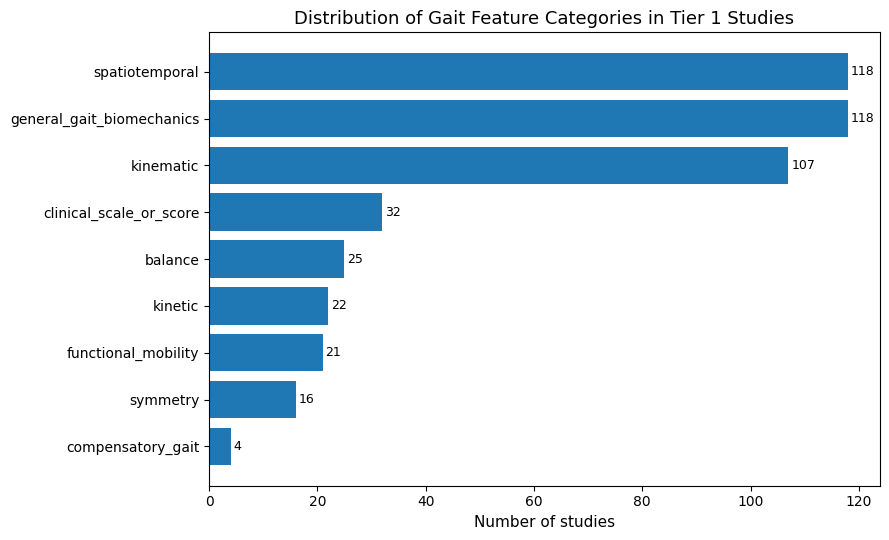

In [60]:
plot_horizontal_bar(
    summary_df=feature_summary,
    label_col="feature_categories_cleaned",
    count_col="count",
    title="Distribution of Gait Feature Categories in Tier 1 Studies",
    xlabel="Number of studies",
    top_n=10,
    save_path=OUTPUT_DIR / "Fig1_feature_categories.png"
)

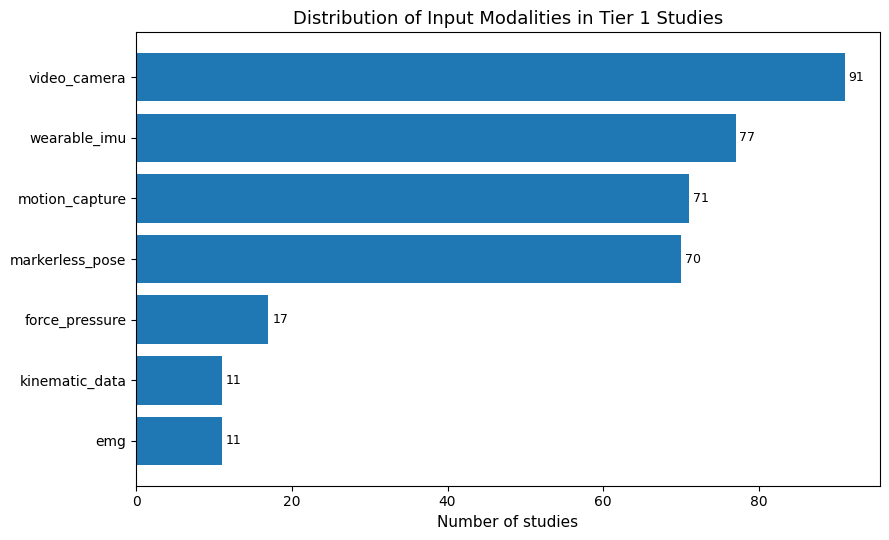

In [61]:
plot_horizontal_bar(
    summary_df=input_summary,
    label_col="input_modality_grouped",
    count_col="count",
    title="Distribution of Input Modalities in Tier 1 Studies",
    xlabel="Number of studies",
    top_n=10,
    save_path=OUTPUT_DIR / "Fig2_input_modalities.png"
)

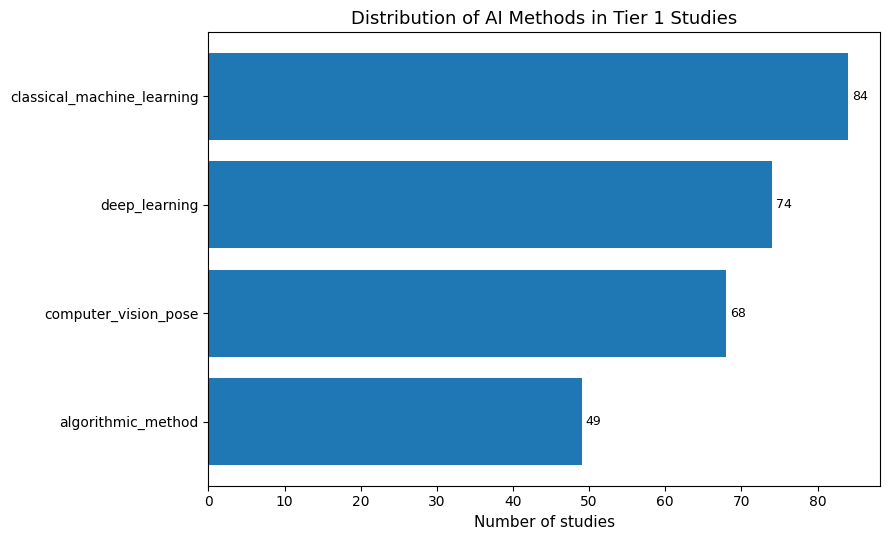

In [62]:
plot_horizontal_bar(
    summary_df=method_summary,
    label_col="ai_method_grouped",
    count_col="count",
    title="Distribution of AI Methods in Tier 1 Studies",
    xlabel="Number of studies",
    top_n=10,
    save_path=OUTPUT_DIR / "Fig3_ai_methods.png"
)

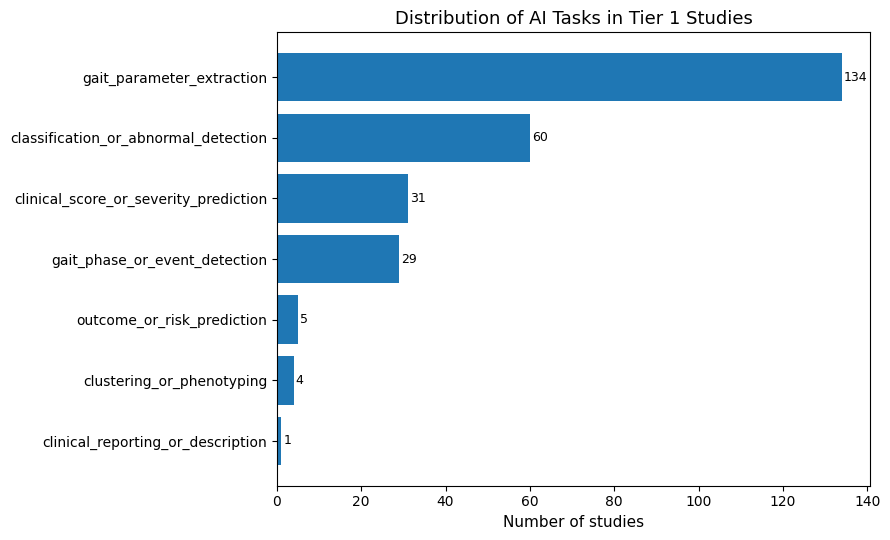

In [63]:
plot_horizontal_bar(
    summary_df=task_summary,
    label_col="ai_task_grouped",
    count_col="count",
    title="Distribution of AI Tasks in Tier 1 Studies",
    xlabel="Number of studies",
    top_n=10,
    save_path=OUTPUT_DIR / "Fig4_ai_tasks.png"
)

In [72]:
# 重新从 cleaned df 生成 disease_summary 和 interpret_summary
disease_summary = (
    df["llm_disease_group"]
    .fillna("not_reported")
    .value_counts()
    .reset_index()
)

disease_summary.columns = ["llm_disease_group", "count"]


interpret_summary = (
    df["llm_clinical_interpretation_level"]
    .fillna("not_reported")
    .value_counts()
    .reset_index()
)

interpret_summary.columns = ["llm_clinical_interpretation_level", "count"]

print("disease_summary:")
print(disease_summary.head())
print(disease_summary.columns.tolist())

print("\ninterpret_summary:")
print(interpret_summary.head())
print(interpret_summary.columns.tolist())

disease_summary:
         llm_disease_group  count
0  neurological_non_stroke     46
1       healthy_or_general     43
2                   stroke     37
3                    mixed     37
4             not_reported     19
['llm_disease_group', 'count']

interpret_summary:
  llm_clinical_interpretation_level  count
0              clinical_description     88
1                    parameter_only     76
2         clinical_score_prediction     30
3                              none      4
4                      not_reported      2
['llm_clinical_interpretation_level', 'count']


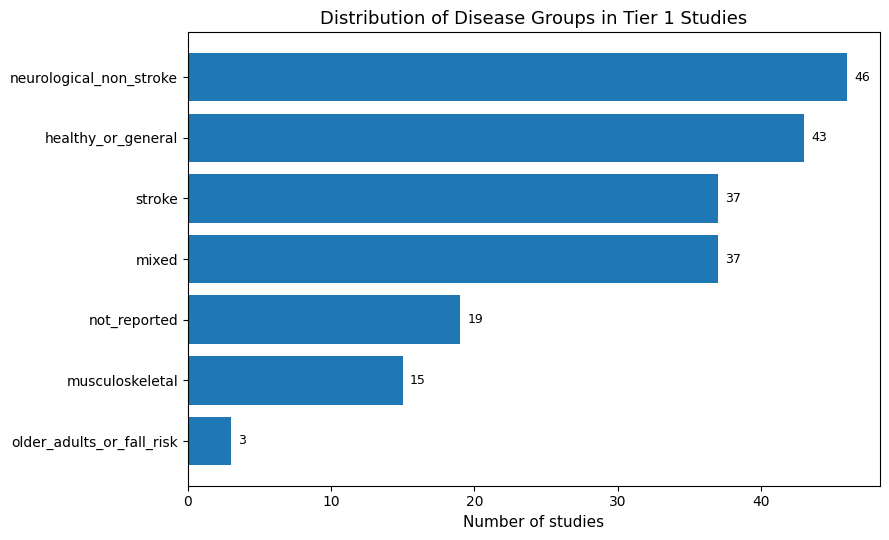

In [73]:
plot_horizontal_bar(
    summary_df=disease_summary,
    label_col="llm_disease_group",
    count_col="count",
    title="Distribution of Disease Groups in Tier 1 Studies",
    xlabel="Number of studies",
    top_n=10,
    save_path=OUTPUT_DIR / "Fig5_disease_groups.png"
)

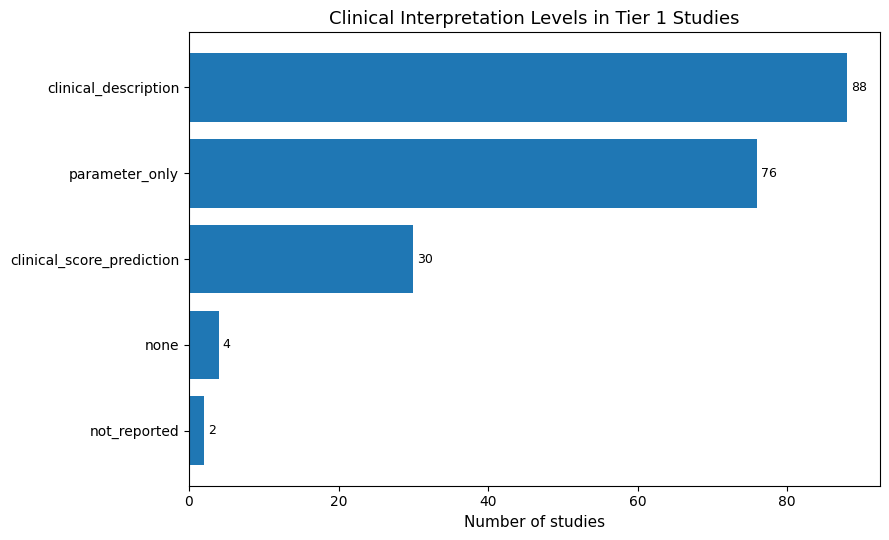

In [74]:
plot_horizontal_bar(
    summary_df=interpret_summary,
    label_col="llm_clinical_interpretation_level",
    count_col="count",
    title="Clinical Interpretation Levels in Tier 1 Studies",
    xlabel="Number of studies",
    top_n=10,
    save_path=OUTPUT_DIR / "Fig6_clinical_interpretation_levels.png"
)